<a href="https://colab.research.google.com/github/reitezuz/18NES2-2026/blob/main/week09/time_series_jena.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Time series prediction - Jena Climate Dataset

Inspired by: https://github.com/fchollet/deep-learning-with-python-notebooks/blob/master/chapter13_timeseries-forecasting.ipynb

# Jena Climate Dataset
The dataset contains meteorological data recorded in Jena, Germany, from 2009 to 2016. Measurement frequency: Every 10 minutes. It is suitable for time series analysis and weather prediction.
- File type: CSV (compressed in a ZIP file).

**Variables:**
- `Datetime` - Date and time of measurement.
- `Temperature (°C)` - Temperature.
- `Pressure (hPa)` - Atmospheric pressure.
- `Humidity (%)` - Relative humidity.
- `Wind speed (m/s)` - Wind speed.
- `Wind direction (°)` - Wind direction in degrees.
- `Radiation (W/m²)` - Solar radiation intensity.
- ...

**Uses:**
- Temperature or other meteorological variable prediction.
- Seasonal and trend analysis in time series data.

**Dataset Source:**

- Dataset download: [jena_climate_2009_2016.csv.zip](https://s3.amazonaws.com/keras-datasets/jena_climate_2009_2016.csv.zip)
- Kaggle: https://www.kaggle.com/datasets/mnassrib/jena-climate


In [ ]:
import os
os.environ["KERAS_BACKEND"] = "jax"

In [ ]:
import keras

print(keras.backend.backend())

tensorflow


## Load, observe and analyze the data

1. Download the zip file with the data
2. Extract the zip file

In [ ]:
!wget https://s3.amazonaws.com/keras-datasets/jena_climate_2009_2016.csv.zip
!unzip jena_climate_2009_2016.csv.zip

import os
# Clean up by removing the downloaded zip file
os.remove("jena_climate_2009_2016.csv.zip")


--2026-11-24 18:42:20--  https://s3.amazonaws.com/keras-datasets/jena_climate_2009_2016.csv.zip
Resolving s3.amazonaws.com (s3.amazonaws.com)... 16.182.67.160, 16.182.96.16, 52.217.171.120, ...
Connecting to s3.amazonaws.com (s3.amazonaws.com)|16.182.67.160|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 13565642 (13M) [application/zip]
Saving to: ‘jena_climate_2009_2016.csv.zip’

jena_climate_2009_2 100%[===================>]  12.94M  4.71MB/s    in 2.7s    

2026-11-24 18:42:23 (4.71 MB/s) - ‘jena_climate_2009_2016.csv.zip’ saved [13565642/13565642]

Archive:  jena_climate_2009_2016.csv.zip
replace jena_climate_2009_2016.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: ^C


### Parse and observe the data

In [ ]:
import pandas as pd
import numpy as np
import os

file_path = "jena_climate_2009_2016.csv"

# Read the CSV file into a pandas DataFrame
df = pd.read_csv(file_path)

# Extract header and number of rows using pandas
header = list(df.columns)
num_rows = len(df)

# Extract 'Temperature (°C)' column into temperature array
temperature = df['T (degC)'].values

# Create raw_data array (excluding the Date Time column)
raw_data_un = df.drop(columns=['Date Time']).values

print("Header:", header)
print("Number of columns:", len(header))
print("Number of rows:", num_rows)
print("Temperature array shape:", temperature.shape)
print("Raw data array shape:", raw_data_un.shape)

# Example: Display first few rows of the DataFrame
display(df.head())


Header: ['Date Time', 'p (mbar)', 'T (degC)', 'Tpot (K)', 'Tdew (degC)', 'rh (%)', 'VPmax (mbar)', 'VPact (mbar)', 'VPdef (mbar)', 'sh (g/kg)', 'H2OC (mmol/mol)', 'rho (g/m**3)', 'wv (m/s)', 'max. wv (m/s)', 'wd (deg)']
Number of columns: 15
Number of rows: 420451
Temperature array shape: (420451,)
Raw data array shape: (420451, 14)


,Date Time,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg)
0,01.01.2009 00:10:00,996.52,-8.02,265.40,-8.90,93.3,3.33,3.11,0.22,1.94,3.12,1307.75,1.03,1.75,152.3
1,01.01.2009 00:20:00,996.57,-8.41,265.01,-9.28,93.4,3.23,3.02,0.21,1.89,3.03,1309.80,0.72,1.50,136.1
2,01.01.2009 00:30:00,996.53,-8.51,264.91,-9.31,93.9,3.21,3.01,0.20,1.88,3.02,1310.24,0.19,0.63,171.6
3,01.01.2009 00:40:00,996.51,-8.31,265.12,-9.07,94.2,3.26,3.07,0.19,1.92,3.08,1309.19,0.34,0.50,198.0
4,01.01.2009 00:50:00,996.51,-8.27,265.15,-9.04,94.1,3.27,3.08,0.19,1.92,3.09,1309.00,0.32,0.63,214.3


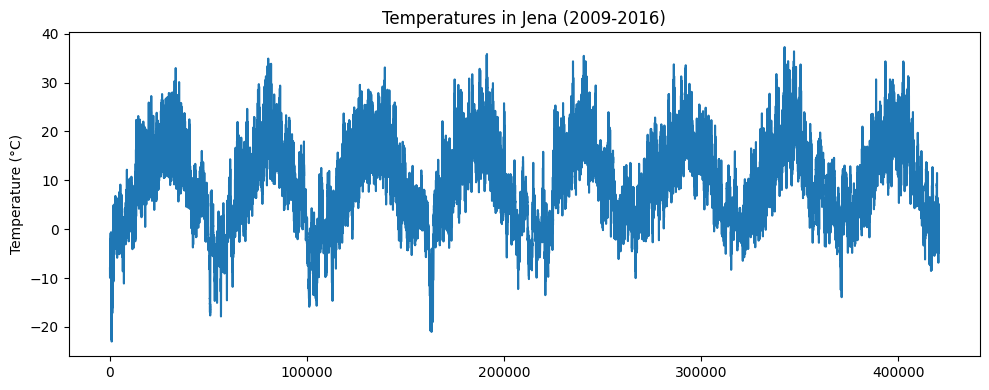

In [ ]:
# Plotting the temperature timeseries
from matplotlib import pyplot as plt

plt.figure(figsize=(10, 4))
plt.plot(range(len(temperature)), temperature)
plt.title("Temperatures in Jena (2009-2016)")
#plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.tight_layout()
plt.show()

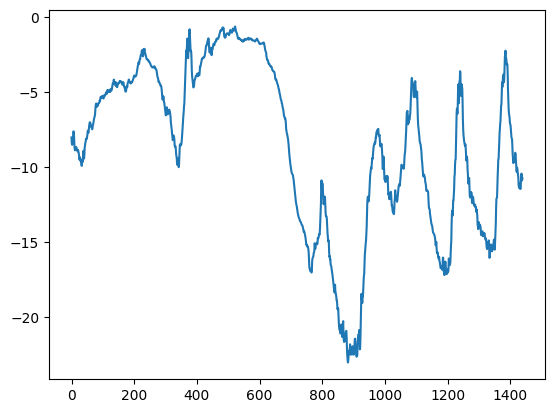

In [ ]:
# Plotting the first 10 days of the temperature timeseries (24*6 = 144 points per day)
plt.plot(range(1440), temperature[:1440])

#### Observation
- We can observe periodicity over multiple timescales:
  - it is more reliable for months and less for days

### General example: creating a data loader for time series data
- create a data loader (dataset) for the time series data
- https://keras.io/api/data_loading/timeseries/

In [ ]:
import numpy as np
import keras

int_sequence = np.arange(10) # 0,..,9
print(int_sequence)

dummy_dataset = keras.utils.timeseries_dataset_from_array(
    data=int_sequence[:-3],
    targets=int_sequence[3:],
    sequence_length=3,
    batch_size=2,
)

for inputs, targets in dummy_dataset:
    print("")
    for i in range(inputs.shape[0]):
        print([int(x) for x in inputs[i]], int(targets[i]))


[0 1 2 3 4 5 6 7 8 9]

[0, 1, 2] 3
[1, 2, 3] 4

[2, 3, 4] 5
[3, 4, 5] 6

[4, 5, 6] 7


### Our task

- We will use only data measured once per hour instead of all data (measured every 10 minutes).
- Based on the values from the previous 5 days, we will predict the temperature 24 hours ahead.
   - 24 points per day, 120 points in 5 days

### Prepare the data
- Normalize the data
- Divide the data into training (50%), validation (25%) and testing (25%) subset
  - The validation and test data should be more recent then the training data.

In [ ]:
import numpy as np
import keras

raw_data = raw_data_un.copy()

# Training, validation and testing data sizes
num_train_samples = int(0.5 * len(raw_data)) # 50 % training data
num_val_samples = int(0.25 * len(raw_data))  # 25 % validation and testing data
num_test_samples = len(raw_data) - num_train_samples - num_val_samples

print("num_train_samples:", num_train_samples)
print("num_val_samples:", num_val_samples)
print("num_test_samples:", num_test_samples)

# Normalize the data:
mean_data = raw_data[:num_train_samples].mean(axis=0)
raw_data -= mean_data
std_data = raw_data[:num_train_samples].std(axis=0)
raw_data /= std_data

print(np.mean(raw_data))

num_train_samples: 210225
num_val_samples: 105112
num_test_samples: 105114
0.03616322533376961


In [ ]:
# Create the training, validation and testing data sets:
sampling_rate = 6        # we will use each 6th sample (1 per hour)
sequence_length = 120    # we will use data from 120 hours (5 days)
delay = sampling_rate * (sequence_length + 24 - 1) # target: value 24 hours after the end of sequence
batch_size = 256

train_dataset = keras.utils.timeseries_dataset_from_array(
    raw_data[:-delay],
    targets=temperature[delay:],
    sampling_rate=sampling_rate,
    sequence_length=sequence_length,
    shuffle=True,
    batch_size=batch_size,
    start_index=0,
    end_index=num_train_samples)

val_dataset = keras.utils.timeseries_dataset_from_array(
    raw_data[:-delay],
    targets=temperature[delay:],
    sampling_rate=sampling_rate,
    sequence_length=sequence_length,
    shuffle=True,
    batch_size=batch_size,
    start_index=num_train_samples,
    end_index=num_train_samples + num_val_samples)

test_dataset = keras.utils.timeseries_dataset_from_array(
    raw_data[:-delay],
    targets=temperature[delay:],
    sampling_rate=sampling_rate,
    sequence_length=sequence_length,
    #shuffle=True,
    batch_size=batch_size,
    start_index=num_train_samples + num_val_samples)


for samples, targets in train_dataset:
    print("samples shape:", samples.shape)
    print("targets shape:", targets.shape)
    break
print("Number of batches:", len(train_dataset))

samples shape: (256, 120, 14)
targets shape: (256,)
Number of batches: 819


In [ ]:
# Data frame for results
import pandas as pd

columns = ["Model Name", "Details", "Train MAE", "Train RMSE", "Val RMSE", "Val MAE", "Test MAE", "Test RMSE", "Time (s)", "Epochs",  ]
results_df = pd.DataFrame(columns=columns)

## Baseline model: Naive last value predictor
- predict the temperature 24 hours ago (i.e., the last measured temperature)
- compute the error (MAE, RMSE) for the baseline model

In [ ]:
def collect_naive_predictions(dataset, mean, std):
    preds_all = []
    targets_all = []

    for samples, targets in dataset:
        # last values * std + mean
        preds = samples[:, -1, 1] * std[1] + mean[1]
        targets = targets
        preds_all.append(preds)         # preds has shape (batch,)
        targets_all.append(targets)     # targets has shape (batch,)

    # concatenate batched results
    preds_all = np.concatenate(preds_all)
    targets_all = np.concatenate(targets_all)

    return preds_all, targets_all

In [ ]:
# Predict on train, val, and test sets
y_train_base, y_train_true = collect_naive_predictions(train_dataset, mean_data, std_data)
y_val_base, y_val_true = collect_naive_predictions(val_dataset, mean_data, std_data)
y_test_base, y_test_true = collect_naive_predictions(test_dataset, mean_data, std_data)

# Compute metrics
def evaluate_baseline(y_true, y_pred, name=""):
    from sklearn.metrics import mean_absolute_error, mean_squared_error
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    print(f"{name} MAE: {mae:.4f}, RMSE: {rmse:.4f}")
    return mae, rmse


train_mae, train_rmse = evaluate_baseline(y_train_true, y_train_base, "Train")
val_mae, val_rmse = evaluate_baseline(y_val_true, y_val_base, "Validation")
test_mae, test_rmse = evaluate_baseline(y_test_true, y_test_base, "Test")

# Add results to the dataframe:
new_entry = {
    "Model Name" : "Baseline",
    "Details" : "Previous day",
    "Train MAE" : train_mae,
    "Train RMSE" : train_rmse,
     "Val MAE" : val_mae,
     "Val RMSE" : val_rmse,
    "Test MAE" : test_mae,
    "Test RMSE" : test_rmse,
    "Epochs": 0,
    "Time (s)": -1,
}

if results_df.empty or "results_df" not in globals():
    results_df = pd.DataFrame([new_entry])
else:
    results_df = pd.concat([results_df, pd.DataFrame([new_entry])], ignore_index=True)

# View and and save the dataframe:
print("Results:")
display(results_df)
model_dir = "./models/"
if not os.path.exists(os.path.dirname(model_dir)):
    os.makedirs(os.path.dirname(model_dir))
results_df.to_csv("models/jena_results.csv", index=False)


Train MAE: 2.6916, RMSE: 3.4924
Validation MAE: 2.4417, RMSE: 3.1778
Test MAE: 2.6220, RMSE: 3.4268
Results:


,Model Name,Details,Train MAE,Train RMSE,Val MAE,Val RMSE,Test MAE,Test RMSE,Epochs,Time (s)
0,Baseline,Previous day,2.691644,3.492441,2.441733,3.177835,2.622036,3.426826,0,-1


## MLP model for time series (same as for regression):
- relu or tanh activation in hidden layers
- Linear activation in the output layer
- Loss: MeanSquaredError or MeanAbsoluteError
- Metrics: MAE, MSE, RMSE


### Define the model

In [ ]:
import keras
from keras import layers
def get_MLP_model():
  # Define model architecture
  inputs = keras.Input(shape=(sequence_length, raw_data.shape[-1],))
  x = layers.Flatten()(inputs)                # flatten the data 120x14 -> 1680
  x = layers.Dense(16, activation="relu")(x)
  outputs = layers.Dense(1)(x)
  model = keras.Model(inputs, outputs)
  return model
model = get_MLP_model()
model.summary()


Model: "functional_23"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_23 (InputLayer)     │ (None, 120, 14)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 1680)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 16)             │        26,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,913 (105.13 KB)

 Trainable params: 26,913 (105.13 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# plot the training progress:
def plot_history(history):
    history_dict = history.history
    print(history_dict.keys())

    from matplotlib import pyplot as plt

    # Plot training & validation accuracy values
    plt.plot(history.history['mae'])
    plt.plot(history.history['val_mae'])
    plt.title('Model MAE')
    plt.ylabel('MAE')
    plt.xlabel('Epoch')
    plt.legend(['Train', 'Validation'], loc='upper left')
    plt.show()

    # Plot training & validation loss values
    plt.plot(history.history['loss'])
    plt.plot(history.history['val_loss'])
    plt.title('Model loss')
    plt.ylabel('Loss')
    plt.xlabel('Epoch')
    plt.legend(['Train', 'Validation'], loc='upper left')
    plt.show()

### Train the model

Epoch 1/10


/home/zuzka/test_tf/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1795563858.991796   75291 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_3740692__.10


818/819 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 14.7289 - mae: 2.9171 - rmse: 3.8378

I0000 00:00:1795563861.363375   75289 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_3740692__.10


819/819 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 14.7264 - mae: 2.9169 - rmse: 3.8375 - val_loss: 11.1913 - val_mae: 2.6366 - val_rmse: 3.3453
Epoch 2/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 9.1561 - mae: 2.3746 - rmse: 3.0259 - val_loss: 10.8018 - val_mae: 2.6034 - val_rmse: 3.2866
Epoch 3/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 8.2918 - mae: 2.2634 - rmse: 2.8796 - val_loss: 10.9188 - val_mae: 2.6137 - val_rmse: 3.3044
Epoch 4/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 7.7455 - mae: 2.1883 - rmse: 2.7831 - val_loss: 10.9231 - val_mae: 2.6208 - val_rmse: 3.3050
Epoch 5/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 7.3563 - mae: 2.1377 - rmse: 2.7123 - val_loss: 11.1722 - val_mae: 2.6431 - val_rmse: 3.3425
Epoch 6/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 6.9961 - mae: 2.0865 - rmse: 2.6450 - val_loss: 11.1187 - val_mae: 2.6438 - val_rmse: 3.3345
Epoch 7/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 6.7412 - mae: 2.0504 - rmse: 2.5

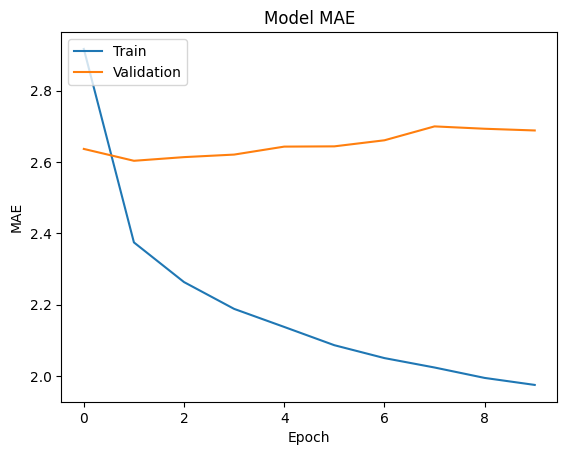

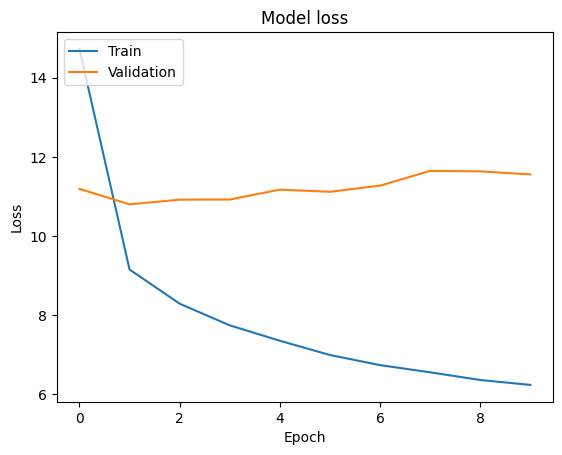

819/819 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 8.4812 - mae: 2.2864 - rmse: 2.9122
408/408 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 10.8018 - mae: 2.6034 - rmse: 3.2866
405/405 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 11.7908 - mae: 2.7044 - rmse: 3.4338
Train      MAE: 2.29, RMSE: 2.91
Validation MAE: 2.60, RMSE: 3.29
Test       MAE: 2.70, RMSE: 3.43
Results:


,Model Name,Details,Train MAE,Train RMSE,Val MAE,Val RMSE,Test MAE,Test RMSE,Epochs,Time (s)
0,Baseline,Previous day,2.691644,3.492441,2.441733,3.177835,2.622036,3.426826,0,-1.000000
1,jena_mlp.keras,,2.286377,2.912248,2.603380,3.286613,2.704371,3.433772,10,32.364558


In [ ]:
# Set some of the hyperparameters:
do_early_stopping = False
do_checkpoint = True
do_tensorboard = True
max_epochs = 10
model_name = "jena_mlp.keras"
details = "" # your comment

###############################################
# Define the model architecture:
model = get_MLP_model()

# Configure the model:
model.compile(optimizer= keras.optimizers.Adam(), # SGD, Adam, RMSProp
              loss= keras.losses.MeanSquaredError(),
              metrics= [keras.metrics.MeanAbsoluteError(name="mae"), keras.metrics.RootMeanSquaredError(name="rmse")])

# Define callbacks (e.g., early stopping):
callbacks = []
if do_early_stopping:
    from keras.callbacks import EarlyStopping
    early_stopping = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
    callbacks.append(early_stopping)
if do_checkpoint:
    from keras.callbacks import ModelCheckpoint
    checkpoint =     keras.callbacks.ModelCheckpoint(
        filepath="./models/" + model_name,
        save_best_only=True,
        monitor="val_loss")
    callbacks.append(checkpoint)
if do_tensorboard:
    from keras.callbacks import TensorBoard
    tensorboard_callback = TensorBoard(log_dir="./logs_jena/"+model_name, histogram_freq=1, write_steps_per_second=True)
    callbacks.append(tensorboard_callback)

################################################
# Train the model
import time
start_time = time.time()
history = model.fit(train_dataset,
                    epochs=max_epochs,
                    validation_data=val_dataset,
                    callbacks=callbacks)
time_fit = time.time() - start_time

###############################
# Plot the training progress:
plot_history(history)

if do_checkpoint:
    # Load the best model
    model = keras.models.load_model("./models/" + model_name)


# Evaluate the model on the training, validation and test sets
train_loss, train_mae, train_rmse = model.evaluate(train_dataset)
val_loss, val_mae, val_rmse = model.evaluate(val_dataset)
test_loss, test_mae, test_rmse = model.evaluate(test_dataset)

print(f"Train      MAE: {train_mae:.2f}, RMSE: {train_rmse:.2f}")
print(f"Validation MAE: {val_mae:.2f}, RMSE: {val_rmse:.2f}")
print(f"Test       MAE: {test_mae:.2f}, RMSE: {test_rmse:.2f}")

###############################
# Save the model:
import os
model_dir = "./models/"
if not os.path.exists(model_dir):
    os.makedirs(model_dir)
model.save(model_dir + model_name)

#################################
# Add results to the dataframe:
new_entry = {
    "Model Name" : model_name,
    "Details" : details,
    "Train MAE" : train_mae,
    "Val MAE" : val_mae,
    "Test MAE" : test_mae,
    "Train RMSE" : train_rmse,
    "Val RMSE" : val_rmse,
    "Test RMSE" : test_rmse,
    "Epochs": max_epochs,
    "Time (s)": time_fit,
}
if 'results_df' not in locals() or results_df is None or results_df.empty:
    results_df = pd.DataFrame([new_entry])
else:
  results_df = pd.concat([results_df, pd.DataFrame([new_entry])], ignore_index=True)

# View and and save the dataframe:
print("Results:")
display(results_df)
results_df.to_csv("models/jena_results.csv", index=False)



In [ ]:
import matplotlib.pyplot as plt

def plot_predictions(dataset, model, num_samples=60, start_index=0):
    """Plots predicted vs. real outputs starting from a specific index."""
    preds_list = []
    targets_list = []

    samples_seen = 0
    total_seen = 0

    for samples, targets in dataset:
        batch_size = samples.shape[0]
        if total_seen + batch_size <= start_index:
            total_seen += batch_size
            continue

        batch_start_index = max(0, start_index - total_seen)

        preds = model.predict(samples, verbose = 0)
        preds_list.extend(preds.reshape(-1)[batch_start_index:])
        targets_list.extend(targets[batch_start_index:])

        samples_seen += batch_size - batch_start_index
        total_seen += batch_size

        if samples_seen >= num_samples:
            break

    # Shorten to the specified number of samples
    preds_list = preds_list[:num_samples]
    targets_list = targets_list[:num_samples]

    plt.figure(figsize=(10, 3))
    plt.plot(targets_list, label='Real Values')
    plt.plot(preds_list, label='Predicted Values')
    plt.xlabel('Sample Index')
    plt.ylabel('Temperature (°C)')
    plt.title('Predicted vs. Real Temperature')
    plt.legend()
    plt.show()


### Observe the results

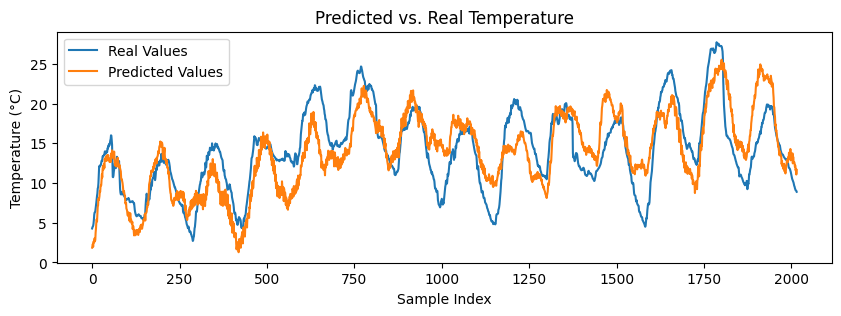

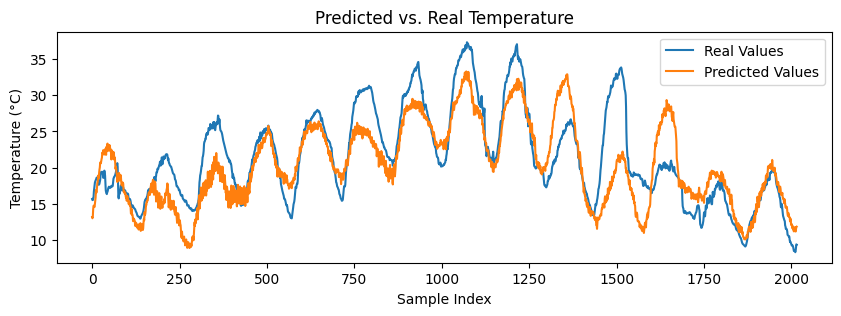

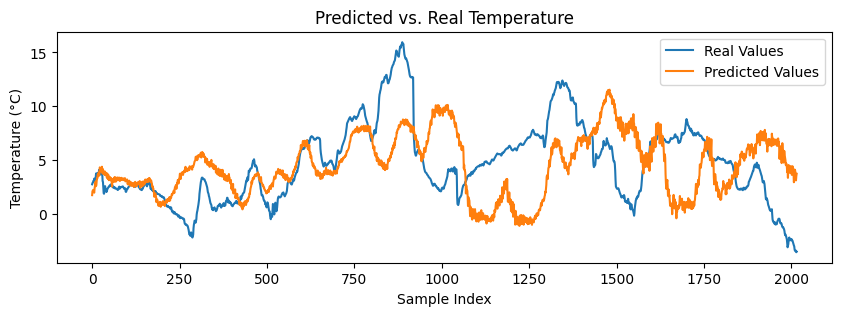

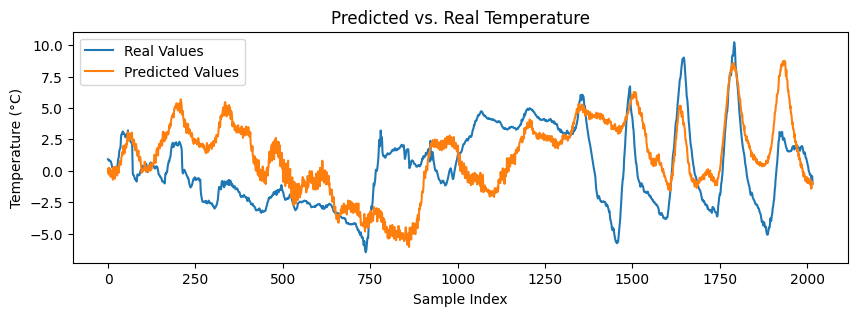

In [ ]:
model = keras.models.load_model("models/jena_mlp.keras")
for start_index in [ (24*6)*4*29,  (24*6)*6*29, 24, (24*6)*1*29,]:
    plot_predictions(test_dataset, model, 24*6*14, start_index) # 14 days samples

## 1D CNN Model

### Define the model

In [ ]:
import keras
from keras import layers

# Define the model architecture:
def get_CNN_model():
    inputs = keras.Input(shape=(sequence_length, raw_data.shape[-1]))

    x = layers.Conv1D(filters=8, kernel_size=24, activation="relu")(inputs)
    x = layers.MaxPooling1D(2)(x)

    x = layers.Conv1D(8, 12, activation="relu")(x)
    x = layers.MaxPooling1D(2)(x)

    x = layers.Conv1D(8, 6, activation="relu")(x)

    # Flatten
    x = layers.GlobalAveragePooling1D()(x)

    outputs = layers.Dense(1)(x) # linear output

    model = keras.Model(inputs=inputs, outputs=outputs)
    return model
model = get_CNN_model()
model.summary()

Model: "functional_25"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_25 (InputLayer)     │ (None, 120, 14)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_6 (Conv1D)               │ (None, 97, 8)          │         2,696 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_4 (MaxPooling1D)  │ (None, 48, 8)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_7 (Conv1D)               │ (None, 37, 8)          │           776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_5 (MaxPooling1D)  │ (None, 18, 8)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_8 (Conv1D)               │ (None, 13, 8)          │           392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_2      │ (None, 8)              │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_30 (Dense)                │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,873 (15.13 KB)

 Trainable params: 3,873 (15.13 KB)

 Non-trainable params: 0 (0.00 B)

### Train the model

Epoch 1/10


/home/zuzka/test_tf/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


819/819 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - loss: 24.6985 - mae: 3.8386 - rmse: 4.9698 - val_loss: 15.1534 - val_mae: 3.0698 - val_rmse: 3.8927
Epoch 2/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 14.6605 - mae: 3.0469 - rmse: 3.8289 - val_loss: 14.1716 - val_mae: 2.9646 - val_rmse: 3.7645
Epoch 3/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 13.0428 - mae: 2.8685 - rmse: 3.6115 - val_loss: 14.1278 - val_mae: 2.9576 - val_rmse: 3.7587
Epoch 4/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 12.0870 - mae: 2.7554 - rmse: 3.4766 - val_loss: 14.2413 - val_mae: 2.9714 - val_rmse: 3.7738
Epoch 5/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 11.3879 - mae: 2.6714 - rmse: 3.3746 - val_loss: 14.4160 - val_mae: 2.9895 - val_rmse: 3.7968
Epoch 6/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 10.8531 - mae: 2.6049 - rmse: 3.2944 - val_loss: 14.3534 - val_mae: 2.9828 - val_rmse: 3.7886
Epoch 7/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 10.4714 - mae: 2.5568 - rms

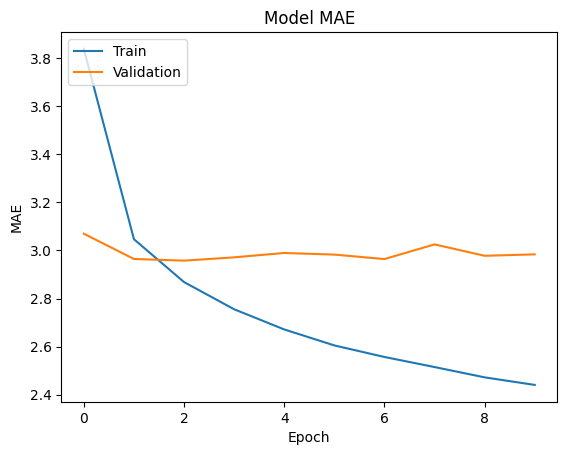

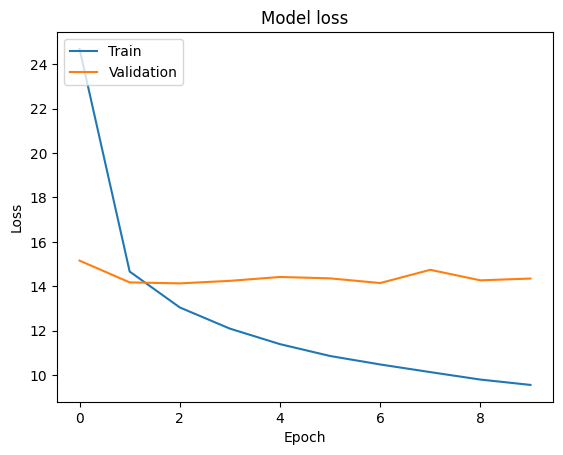

819/819 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 12.2774 - mae: 2.7832 - rmse: 3.5039
408/408 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 14.1278 - mae: 2.9576 - rmse: 3.7587
405/405 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 15.4520 - mae: 3.1040 - rmse: 3.9309
Train      MAE: 2.78, RMSE: 3.50
Validation MAE: 2.96, RMSE: 3.76
Test       MAE: 3.10, RMSE: 3.93
Results:


,Model Name,Details,Train MAE,Train RMSE,Val MAE,Val RMSE,Test MAE,Test RMSE,Epochs,Time (s)
0,Baseline,Previous day,2.691644,3.492441,2.441733,3.177835,2.622036,3.426826,0,-1.000000
1,jena_mlp.keras,,2.286377,2.912248,2.603380,3.286613,2.704371,3.433772,10,32.364558
2,jena_cnn.keras,,2.783204,3.503916,2.957596,3.758692,3.104005,3.930905,10,35.104710


In [ ]:
# Set some of the hyperparameters:
do_early_stopping = False
do_checkpoint = True
do_tensorboard = True
max_epochs = 10
model_name = "jena_cnn.keras"
details = "" # your comment

###############################################
# Define the model architecture:
model = get_CNN_model()

# Configure the model:
model.compile(optimizer= keras.optimizers.Adam(), # SGD, Adam, RMSProp
              loss= keras.losses.MeanSquaredError(),
              metrics= [keras.metrics.MeanAbsoluteError(name="mae"), keras.metrics.RootMeanSquaredError(name="rmse")])

# Define callbacks (e.g., early stopping):
callbacks = []
if do_early_stopping:
    from keras.callbacks import EarlyStopping
    early_stopping = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
    callbacks.append(early_stopping)
if do_checkpoint:
    from keras.callbacks import ModelCheckpoint
    checkpoint =     keras.callbacks.ModelCheckpoint(
        filepath="./models/" + model_name,
        save_best_only=True,
        monitor="val_loss")
    callbacks.append(checkpoint)
if do_tensorboard:
    from keras.callbacks import TensorBoard
    tensorboard_callback = TensorBoard(log_dir="./logs_jena/"+model_name, histogram_freq=1, write_steps_per_second=True)
    callbacks.append(tensorboard_callback)

################################################
# Train the model
import time
start_time = time.time()
history = model.fit(train_dataset,
                    epochs=max_epochs,
                    validation_data=val_dataset,
                    callbacks=callbacks)
time_fit = time.time() - start_time

###############################
# Plot the training progress:
plot_history(history)

if do_checkpoint:
    # Load the best model
    model = keras.models.load_model("./models/" + model_name)


# Evaluate the model on the training, validation and test sets
train_loss, train_mae, train_rmse = model.evaluate(train_dataset)
val_loss, val_mae, val_rmse = model.evaluate(val_dataset)
test_loss, test_mae, test_rmse = model.evaluate(test_dataset)

print(f"Train      MAE: {train_mae:.2f}, RMSE: {train_rmse:.2f}")
print(f"Validation MAE: {val_mae:.2f}, RMSE: {val_rmse:.2f}")
print(f"Test       MAE: {test_mae:.2f}, RMSE: {test_rmse:.2f}")

###############################
# Save the model:
import os
model_dir = "./models/"
if not os.path.exists(model_dir):
    os.makedirs(model_dir)
model.save(model_dir + model_name)

#################################
# Add results to the dataframe:
new_entry = {
    "Model Name" : model_name,
    "Details" : details,
    "Train MAE" : train_mae,
    "Val MAE" : val_mae,
    "Test MAE" : test_mae,
    "Train RMSE" : train_rmse,
    "Val RMSE" : val_rmse,
    "Test RMSE" : test_rmse,
    "Epochs": max_epochs,
    "Time (s)": time_fit,
}
if 'results_df' not in locals() or results_df is None or results_df.empty:
    results_df = pd.DataFrame([new_entry])
else:
  results_df = pd.concat([results_df, pd.DataFrame([new_entry])], ignore_index=True)

# View and and save the dataframe:
print("Results:")
display(results_df)
results_df.to_csv("models/jena_results.csv", index=False)


### Observe the results

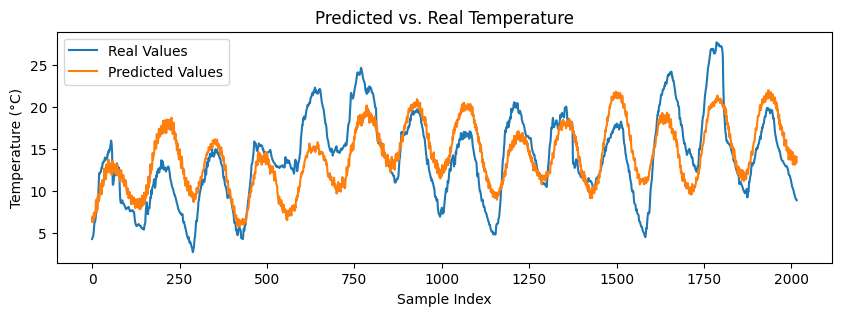

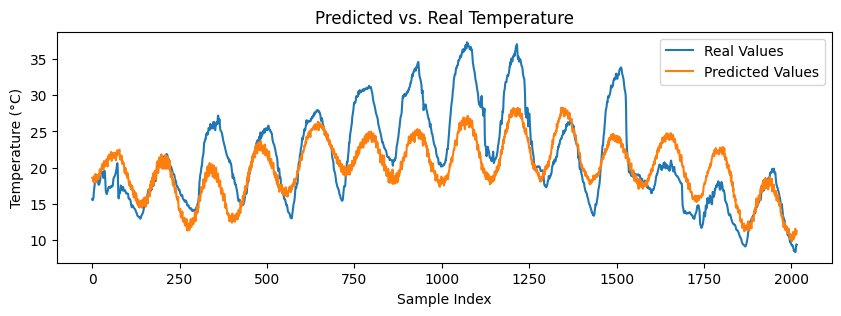

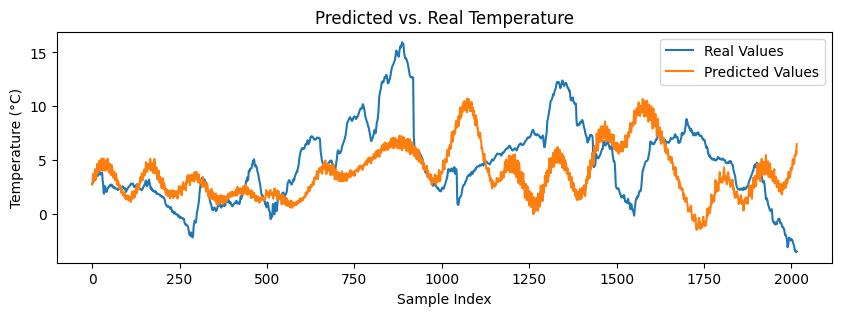

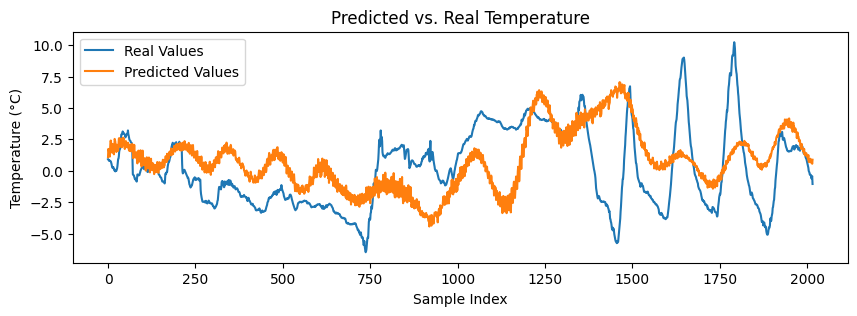

In [ ]:
model = keras.models.load_model("models/jena_cnn.keras")
for start_index in [ (24*6)*4*29,  (24*6)*6*29, 24, (24*6)*1*29,]:
    plot_predictions(test_dataset, model, 24*6*14, start_index) # 14 days samples

## A vanilla RNN model

### Define the model

In [ ]:
import keras
from keras import layers

def get_SimpleRNN_model():
    inputs = keras.Input(shape=(sequence_length, raw_data.shape[-1]))

    x = layers.SimpleRNN(16)(inputs)

    outputs = layers.Dense(1)(x)
    model = keras.Model(inputs, outputs)
    return model

model = get_SimpleRNN_model()
model.summary()

Model: "functional_27"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_27 (InputLayer)     │ (None, 120, 14)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_2 (SimpleRNN)        │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 513 (2.00 KB)

 Trainable params: 513 (2.00 KB)

 Non-trainable params: 0 (0.00 B)

### Train the model

Epoch 1/10


/home/zuzka/test_tf/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1795563944.004474   75291 dot_merger.cc:481] Merging Dots in computation: functional_28_1_simple_rnn_3_1_while_body_4242718_grad_4242914_const_0__.19.clone.clone.clone.clone.clone


812/819 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 51.8897 - mae: 5.3507 - rmse: 7.2034

I0000 00:00:1795563951.108316   75291 dot_merger.cc:481] Merging Dots in computation: functional_28_1_simple_rnn_3_1_while_body_4242718_grad_4242914_const_0__.19.clone.clone.clone.clone.clone


819/819 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - loss: 51.6398 - mae: 5.3350 - rmse: 7.1861 - val_loss: 19.5272 - val_mae: 3.2410 - val_rmse: 4.4190
Epoch 2/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - loss: 14.9334 - mae: 2.9272 - rmse: 3.8644 - val_loss: 11.4521 - val_mae: 2.5554 - val_rmse: 3.3841
Epoch 3/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - loss: 11.6163 - mae: 2.6429 - rmse: 3.4083 - val_loss: 9.9930 - val_mae: 2.4321 - val_rmse: 3.1612
Epoch 4/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - loss: 10.8416 - mae: 2.5666 - rmse: 3.2927 - val_loss: 9.5343 - val_mae: 2.3934 - val_rmse: 3.0878
Epoch 5/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - loss: 10.6516 - mae: 2.5428 - rmse: 3.2637 - val_loss: 9.3421 - val_mae: 2.3770 - val_rmse: 3.0565
Epoch 6/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - loss: 10.3814 - mae: 2.5152 - rmse: 3.2220 - val_loss: 9.2111 - val_mae: 2.3634 - val_rmse: 3.0350
Epoch 7/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - loss: 10.2078 - mae: 2.4935 - rmse:

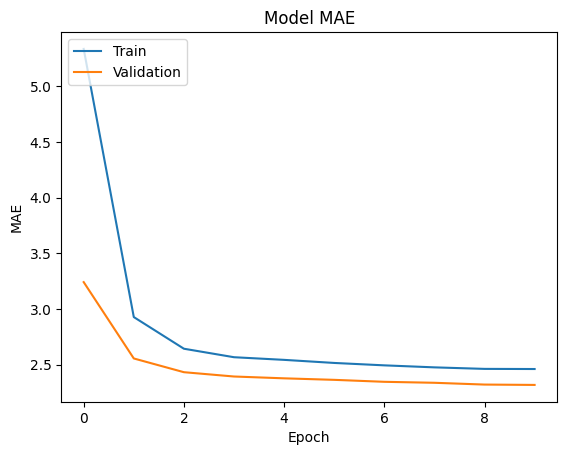

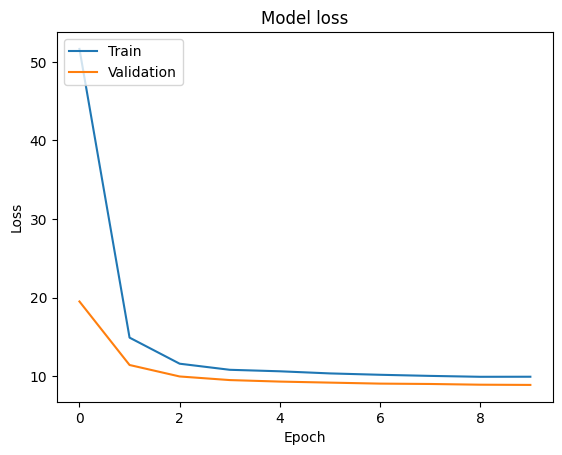

819/819 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 9.9124 - mae: 2.4517 - rmse: 3.1484
408/408 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 8.9182 - mae: 2.3178 - rmse: 2.9863
405/405 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 10.2162 - mae: 2.4753 - rmse: 3.1963
Train      MAE: 2.45, RMSE: 3.15
Validation MAE: 2.32, RMSE: 2.99
Test       MAE: 2.48, RMSE: 3.20
Results:


,Model Name,Details,Train MAE,Train RMSE,Val MAE,Val RMSE,Test MAE,Test RMSE,Epochs,Time (s)
0,Baseline,Previous day,2.691644,3.492441,2.441733,3.177835,2.622036,3.426826,0,-1.000000
1,jena_mlp.keras,,2.286377,2.912248,2.603380,3.286613,2.704371,3.433772,10,32.364558
2,jena_cnn.keras,,2.783204,3.503916,2.957596,3.758692,3.104005,3.930905,10,35.104710
3,jena_simpleRNN.keras,,2.451746,3.148395,2.317821,2.986339,2.475284,3.196283,10,79.530048


In [ ]:
# Set some of the hyperparameters:
do_early_stopping = False
do_checkpoint = True
do_tensorboard = True
max_epochs = 10
model_name = "jena_simpleRNN.keras"
details = "" # your comment

###############################################
# Define the model architecture:
model = get_SimpleRNN_model()

# Configure the model:
model.compile(optimizer= keras.optimizers.Adam(), # SGD, Adam, RMSProp
              loss= keras.losses.MeanSquaredError(),
              metrics= [keras.metrics.MeanAbsoluteError(name="mae"), keras.metrics.RootMeanSquaredError(name="rmse")])

# Define callbacks (e.g., early stopping):
callbacks = []
if do_early_stopping:
    from keras.callbacks import EarlyStopping
    early_stopping = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
    callbacks.append(early_stopping)
if do_checkpoint:
    from keras.callbacks import ModelCheckpoint
    checkpoint =     keras.callbacks.ModelCheckpoint(
        filepath="./models/" + model_name,
        save_best_only=True,
        monitor="val_loss")
    callbacks.append(checkpoint)
if do_tensorboard:
    from keras.callbacks import TensorBoard
    tensorboard_callback = TensorBoard(log_dir="./logs_jena/"+model_name, histogram_freq=1, write_steps_per_second=True)
    callbacks.append(tensorboard_callback)

################################################
# Train the model
import time
start_time = time.time()
history = model.fit(train_dataset,
                    epochs=max_epochs,
                    validation_data=val_dataset,
                    callbacks=callbacks)
time_fit = time.time() - start_time

###############################
# Plot the training progress:
plot_history(history)

if do_checkpoint:
    # Load the best model
    model = keras.models.load_model("./models/" + model_name)


# Evaluate the model on the training, validation and test sets
train_loss, train_mae, train_rmse = model.evaluate(train_dataset)
val_loss, val_mae, val_rmse = model.evaluate(val_dataset)
test_loss, test_mae, test_rmse = model.evaluate(test_dataset)

print(f"Train      MAE: {train_mae:.2f}, RMSE: {train_rmse:.2f}")
print(f"Validation MAE: {val_mae:.2f}, RMSE: {val_rmse:.2f}")
print(f"Test       MAE: {test_mae:.2f}, RMSE: {test_rmse:.2f}")

###############################
# Save the model:
import os
model_dir = "./models/"
if not os.path.exists(model_dir):
    os.makedirs(model_dir)
model.save(model_dir + model_name)

#################################
# Add results to the dataframe:
new_entry = {
    "Model Name" : model_name,
    "Details" : details,
    "Train MAE" : train_mae,
    "Val MAE" : val_mae,
    "Test MAE" : test_mae,
    "Train RMSE" : train_rmse,
    "Val RMSE" : val_rmse,
    "Test RMSE" : test_rmse,
    "Epochs": max_epochs,
    "Time (s)": time_fit,
}
if 'results_df' not in locals() or results_df is None or results_df.empty:
    results_df = pd.DataFrame([new_entry])
else:
  results_df = pd.concat([results_df, pd.DataFrame([new_entry])], ignore_index=True)

# View and and save the dataframe:
print("Results:")
display(results_df)
results_df.to_csv("models/jena_results.csv", index=False)


### Observe the results

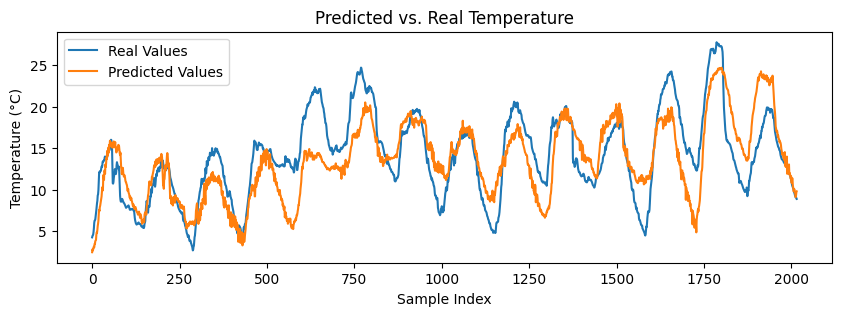

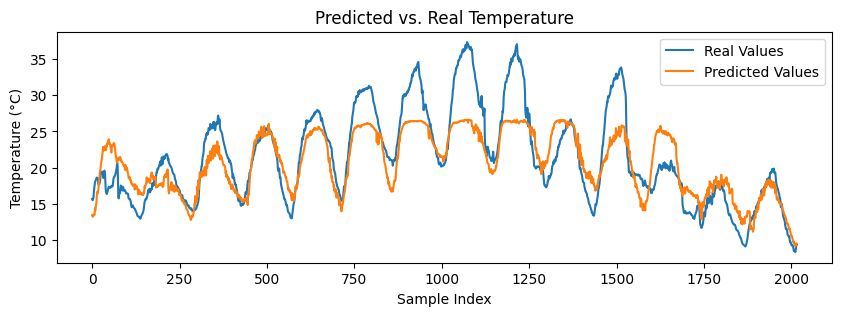

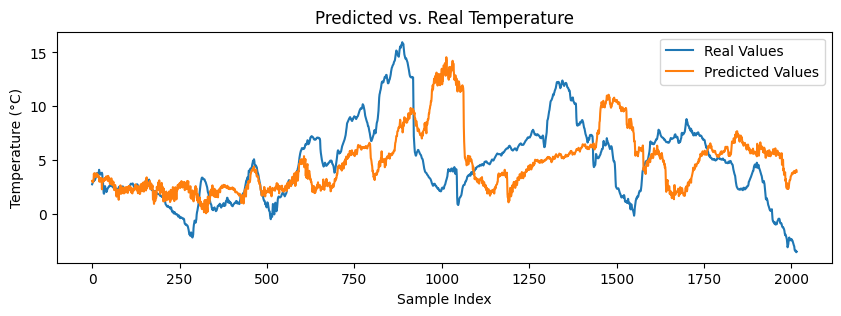

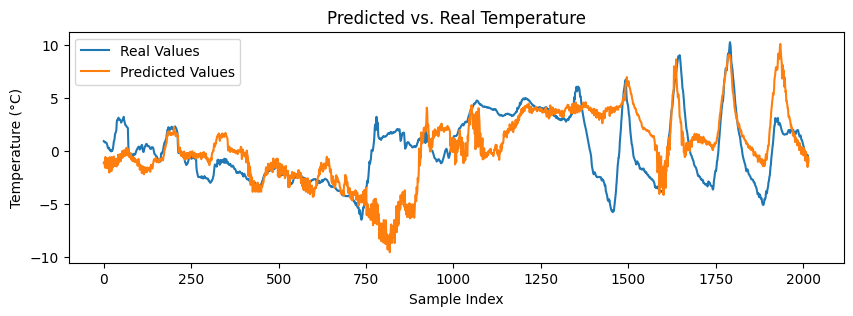

In [ ]:
model = keras.models.load_model("models/jena_simpleRNN.keras")
for start_index in [ (24*6)*4*29,  (24*6)*6*29, 24, (24*6)*1*29,]:
    plot_predictions(test_dataset, model, 24*6*14, start_index) # 14 days samples

In [ ]:
#results_df

In [ ]:
#results_df = results_df.drop(4, axis=0).reset_index(drop=True)

In [ ]:
# results_df = pd.read_csv("models/jena_results.csv")

## LSTM

#### Define the model

In [ ]:
import keras
from keras import layers

def get_LSTM_model():
    inputs = keras.Input(shape=(sequence_length, raw_data.shape[-1]))

    x = layers.LSTM(16)(inputs)

    outputs = layers.Dense(1)(x)
    model = keras.Model(inputs, outputs)
    return model
model = get_LSTM_model()
model.summary()

Model: "functional_29"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_29 (InputLayer)     │ (None, 120, 14)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_9 (LSTM)                   │ (None, 16)             │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_34 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,001 (7.82 KB)

 Trainable params: 2,001 (7.82 KB)

 Non-trainable params: 0 (0.00 B)

### Train the model

Epoch 1/20


/home/zuzka/test_tf/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


819/819 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - loss: 49.9019 - mae: 5.2565 - rmse: 7.0641 - val_loss: 19.2655 - val_mae: 3.2552 - val_rmse: 4.3892
Epoch 2/20
819/819 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - loss: 15.8674 - mae: 3.0150 - rmse: 3.9834 - val_loss: 11.5702 - val_mae: 2.5888 - val_rmse: 3.4015
Epoch 3/20
819/819 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - loss: 11.7868 - mae: 2.6548 - rmse: 3.4332 - val_loss: 9.9175 - val_mae: 2.4271 - val_rmse: 3.1492
Epoch 4/20
819/819 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - loss: 10.3859 - mae: 2.5083 - rmse: 3.2227 - val_loss: 9.4857 - val_mae: 2.3763 - val_rmse: 3.0799
Epoch 5/20
819/819 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - loss: 9.5286 - mae: 2.4071 - rmse: 3.0868 - val_loss: 9.5050 - val_mae: 2.3854 - val_rmse: 3.0830
Epoch 6/20
819/819 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - loss: 9.2982 - mae: 2.3803 - rmse: 3.0493 - val_loss: 9.3680 - val_mae: 2.3650 - val_rmse: 3.0607
Epoch 7/20
819/819 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - loss: 8.7202 - mae: 2.3117 - rmse: 2.95

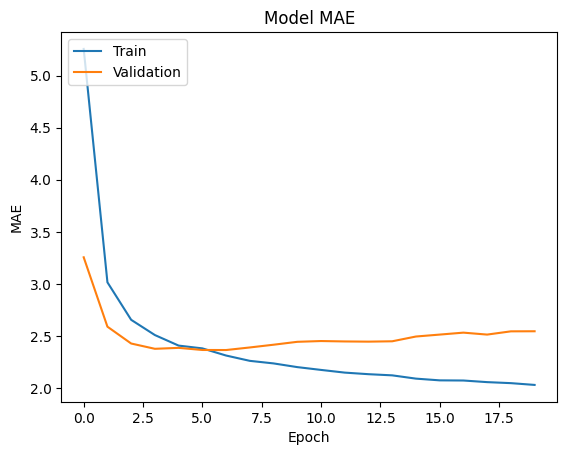

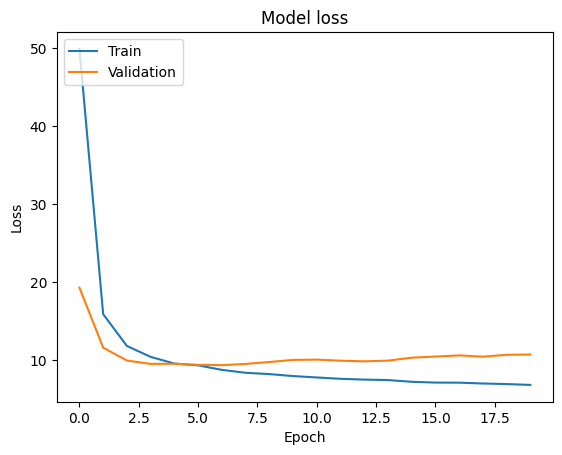

819/819 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 8.4657 - mae: 2.2821 - rmse: 2.9096
408/408 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 9.3255 - mae: 2.3646 - rmse: 3.0538
405/405 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 10.3820 - mae: 2.5182 - rmse: 3.2221
Train      MAE: 2.28, RMSE: 2.91
Validation MAE: 2.36, RMSE: 3.05
Test       MAE: 2.52, RMSE: 3.22
Results:


,Model Name,Details,Train MAE,Train RMSE,Val MAE,Val RMSE,Test MAE,Test RMSE,Epochs,Time (s)
0,Baseline,Previous day,2.691644,3.492441,2.441733,3.177835,2.622036,3.426826,0,-1.000000
1,jena_mlp.keras,,2.286377,2.912248,2.603380,3.286613,2.704371,3.433772,10,32.364558
2,jena_cnn.keras,,2.783204,3.503916,2.957596,3.758692,3.104005,3.930905,10,35.104710
3,jena_simpleRNN.keras,,2.451746,3.148395,2.317821,2.986339,2.475284,3.196283,10,79.530048
4,jena_lstm.keras,,2.282090,2.909583,2.364570,3.053765,2.518209,3.222106,20,105.702224


In [ ]:
# Set some of the hyperparameters:
do_early_stopping = False
do_checkpoint = True
do_tensorboard = True
max_epochs = 20
model_name = "jena_lstm.keras"
details = "" # your comment

###############################################
# Define the model architecture:
model = get_LSTM_model()

# Configure the model:
model.compile(optimizer= keras.optimizers.Adam(), # SGD, Adam, RMSProp
              loss= keras.losses.MeanSquaredError(),
              metrics= [keras.metrics.MeanAbsoluteError(name="mae"), keras.metrics.RootMeanSquaredError(name="rmse")])

# Define callbacks (e.g., early stopping):
callbacks = []
if do_early_stopping:
    from keras.callbacks import EarlyStopping
    early_stopping = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
    callbacks.append(early_stopping)
if do_checkpoint:
    from keras.callbacks import ModelCheckpoint
    checkpoint =     keras.callbacks.ModelCheckpoint(
        filepath="./models/" + model_name,
        save_best_only=True,
        monitor="val_loss")
    callbacks.append(checkpoint)
if do_tensorboard:
    from keras.callbacks import TensorBoard
    tensorboard_callback = TensorBoard(log_dir="./logs_jena/"+model_name, histogram_freq=1, write_steps_per_second=True)
    callbacks.append(tensorboard_callback)

################################################
# Train the model
import time
start_time = time.time()
history = model.fit(train_dataset,
                    epochs=max_epochs,
                    validation_data=val_dataset,
                    callbacks=callbacks)
time_fit = time.time() - start_time

###############################
# Plot the training progress:
plot_history(history)

if do_checkpoint:
    # Load the best model
    model = keras.models.load_model("./models/" + model_name)


# Evaluate the model on the training, validation and test sets
train_loss, train_mae, train_rmse = model.evaluate(train_dataset)
val_loss, val_mae, val_rmse = model.evaluate(val_dataset)
test_loss, test_mae, test_rmse = model.evaluate(test_dataset)

print(f"Train      MAE: {train_mae:.2f}, RMSE: {train_rmse:.2f}")
print(f"Validation MAE: {val_mae:.2f}, RMSE: {val_rmse:.2f}")
print(f"Test       MAE: {test_mae:.2f}, RMSE: {test_rmse:.2f}")

###############################
# Save the model:
import os
model_dir = "./models/"
if not os.path.exists(model_dir):
    os.makedirs(model_dir)
model.save(model_dir + model_name)

#################################
# Add results to the dataframe:
new_entry = {
    "Model Name" : model_name,
    "Details" : details,
    "Train MAE" : train_mae,
    "Val MAE" : val_mae,
    "Test MAE" : test_mae,
    "Train RMSE" : train_rmse,
    "Val RMSE" : val_rmse,
    "Test RMSE" : test_rmse,
    "Epochs": max_epochs,
    "Time (s)": time_fit,
}
if 'results_df' not in locals() or results_df is None or results_df.empty:
    results_df = pd.DataFrame([new_entry])
else:
  results_df = pd.concat([results_df, pd.DataFrame([new_entry])], ignore_index=True)

# View and and save the dataframe:
print("Results:")
display(results_df)
results_df.to_csv("models/jena_results.csv", index=False)


### Observe the results

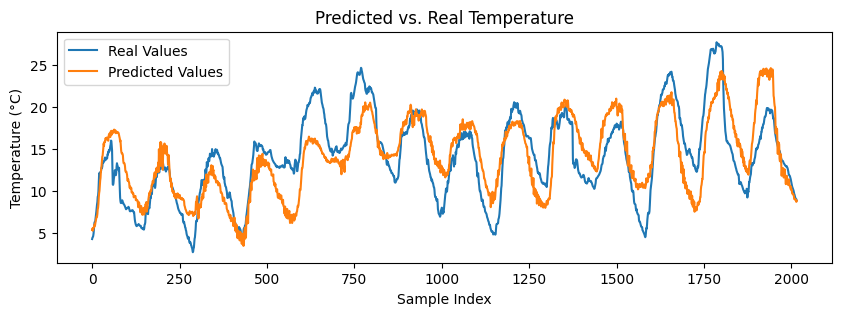

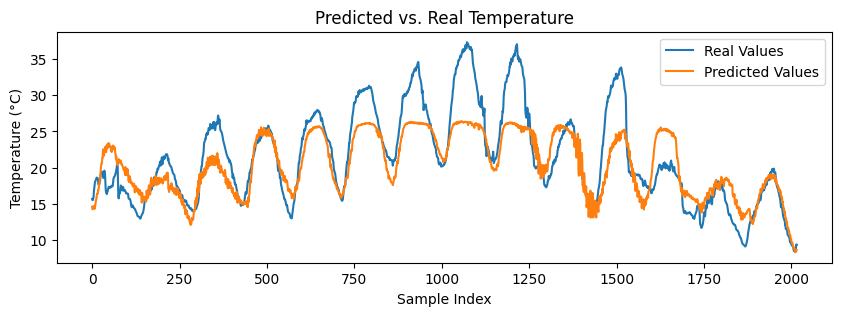

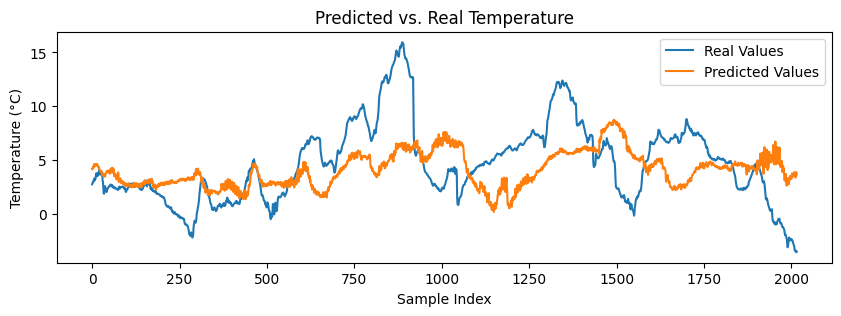

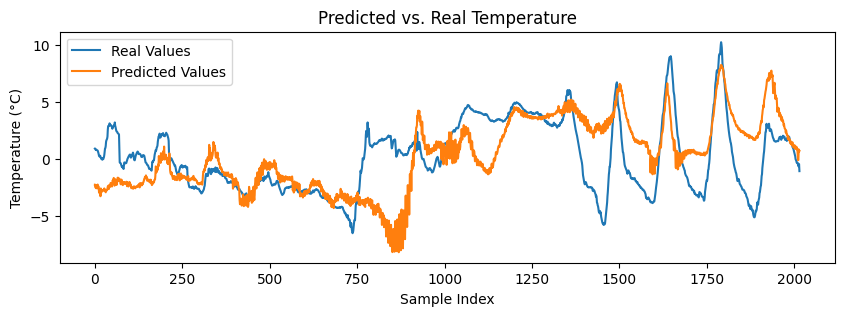

In [ ]:
model = keras.models.load_model("models/jena_lstm.keras")
for start_index in [ (24*6)*4*29,  (24*6)*6*29, 24, (24*6)*1*29,]:
    plot_predictions(test_dataset, model, 24*6*14, start_index) # 14 days samples

## GRU

### Define the model

In [ ]:
import keras
from keras import layers

def get_GRU_model():
    inputs = keras.Input(shape=(sequence_length, raw_data.shape[-1]))

    x = layers.GRU(16)(inputs) # change

    outputs = layers.Dense(1)(x)
    model = keras.Model(inputs, outputs)
    return model
model = get_GRU_model()
model.summary()

Model: "functional_31"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_31 (InputLayer)     │ (None, 120, 14)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_12 (GRU)                    │ (None, 16)             │         1,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_36 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,553 (6.07 KB)

 Trainable params: 1,553 (6.07 KB)

 Non-trainable params: 0 (0.00 B)

### Train the model

Epoch 1/10


/home/zuzka/test_tf/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


819/819 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - loss: 43.9882 - mae: 4.8841 - rmse: 6.6324 - val_loss: 17.4824 - val_mae: 3.0843 - val_rmse: 4.1812
Epoch 2/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 13.4816 - mae: 2.7800 - rmse: 3.6717 - val_loss: 11.1988 - val_mae: 2.5344 - val_rmse: 3.3465
Epoch 3/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 10.4007 - mae: 2.4886 - rmse: 3.2250 - val_loss: 9.9623 - val_mae: 2.4232 - val_rmse: 3.1563
Epoch 4/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 9.4302 - mae: 2.3789 - rmse: 3.0709 - val_loss: 9.6585 - val_mae: 2.3957 - val_rmse: 3.1078
Epoch 5/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 8.9484 - mae: 2.3225 - rmse: 2.9914 - val_loss: 9.6850 - val_mae: 2.3983 - val_rmse: 3.1121
Epoch 6/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 8.5638 - mae: 2.2775 - rmse: 2.9264 - val_loss: 10.0760 - val_mae: 2.4395 - val_rmse: 3.1743
Epoch 7/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 8.2185 - mae: 2.2367 - rmse: 2.86

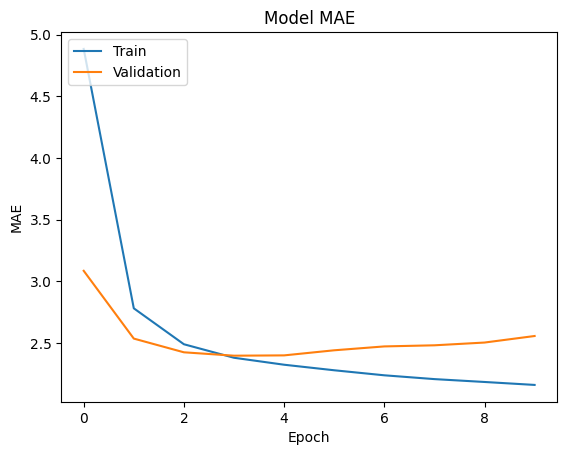

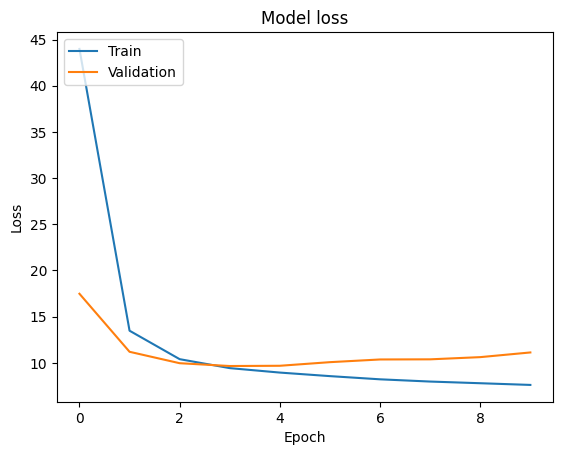

819/819 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 9.1165 - mae: 2.3388 - rmse: 3.0194
408/408 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 9.6585 - mae: 2.3957 - rmse: 3.1078
405/405 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 10.7854 - mae: 2.5729 - rmse: 3.2841
Train      MAE: 2.34, RMSE: 3.02
Validation MAE: 2.40, RMSE: 3.11
Test       MAE: 2.57, RMSE: 3.28
Results:


,Model Name,Details,Train MAE,Train RMSE,Val MAE,Val RMSE,Test MAE,Test RMSE,Epochs,Time (s)
0,Baseline,Previous day,2.691644,3.492441,2.441733,3.177835,2.622036,3.426826,0,-1.000000
1,jena_mlp.keras,,2.286377,2.912248,2.603380,3.286613,2.704371,3.433772,10,32.364558
2,jena_cnn.keras,,2.783204,3.503916,2.957596,3.758692,3.104005,3.930905,10,35.104710
3,jena_simpleRNN.keras,,2.451746,3.148395,2.317821,2.986339,2.475284,3.196283,10,79.530048
4,jena_lstm.keras,,2.282090,2.909583,2.364570,3.053765,2.518209,3.222106,20,105.702224
5,jena_gru.keras,,2.338784,3.019350,2.395717,3.107807,2.572892,3.284117,10,54.666981


In [ ]:
# Set some of the hyperparameters:
do_early_stopping = False
do_checkpoint = True
do_tensorboard = True
max_epochs = 10
model_name = "jena_gru.keras"
details = "" # your comment

###############################################
# Define the model architecture:
model = get_GRU_model()

# Configure the model:
model.compile(optimizer= keras.optimizers.Adam(), # SGD, Adam, RMSProp
              loss= keras.losses.MeanSquaredError(),
              metrics= [keras.metrics.MeanAbsoluteError(name="mae"), keras.metrics.RootMeanSquaredError(name="rmse")])

# Define callbacks (e.g., early stopping):
callbacks = []
if do_early_stopping:
    from keras.callbacks import EarlyStopping
    early_stopping = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
    callbacks.append(early_stopping)
if do_checkpoint:
    from keras.callbacks import ModelCheckpoint
    checkpoint =     keras.callbacks.ModelCheckpoint(
        filepath="./models/" + model_name,
        save_best_only=True,
        monitor="val_loss")
    callbacks.append(checkpoint)
if do_tensorboard:
    from keras.callbacks import TensorBoard
    tensorboard_callback = TensorBoard(log_dir="./logs_jena/"+model_name, histogram_freq=1, write_steps_per_second=True)
    callbacks.append(tensorboard_callback)

################################################
# Train the model
import time
start_time = time.time()
history = model.fit(train_dataset,
                    epochs=max_epochs,
                    validation_data=val_dataset,
                    callbacks=callbacks)
time_fit = time.time() - start_time

###############################
# Plot the training progress:
plot_history(history)

if do_checkpoint:
    # Load the best model
    model = keras.models.load_model("./models/" + model_name)


# Evaluate the model on the training, validation and test sets
train_loss, train_mae, train_rmse = model.evaluate(train_dataset)
val_loss, val_mae, val_rmse = model.evaluate(val_dataset)
test_loss, test_mae, test_rmse = model.evaluate(test_dataset)

print(f"Train      MAE: {train_mae:.2f}, RMSE: {train_rmse:.2f}")
print(f"Validation MAE: {val_mae:.2f}, RMSE: {val_rmse:.2f}")
print(f"Test       MAE: {test_mae:.2f}, RMSE: {test_rmse:.2f}")

###############################
# Save the model:
import os
model_dir = "./models/"
if not os.path.exists(model_dir):
    os.makedirs(model_dir)
model.save(model_dir + model_name)

#################################
# Add results to the dataframe:
new_entry = {
    "Model Name" : model_name,
    "Details" : details,
    "Train MAE" : train_mae,
    "Val MAE" : val_mae,
    "Test MAE" : test_mae,
    "Train RMSE" : train_rmse,
    "Val RMSE" : val_rmse,
    "Test RMSE" : test_rmse,
    "Epochs": max_epochs,
    "Time (s)": time_fit,
}
if 'results_df' not in locals() or results_df is None or results_df.empty:
    results_df = pd.DataFrame([new_entry])
else:
  results_df = pd.concat([results_df, pd.DataFrame([new_entry])], ignore_index=True)

# View and and save the dataframe:
print("Results:")
display(results_df)
results_df.to_csv("models/jena_results.csv", index=False)


### Observe the results

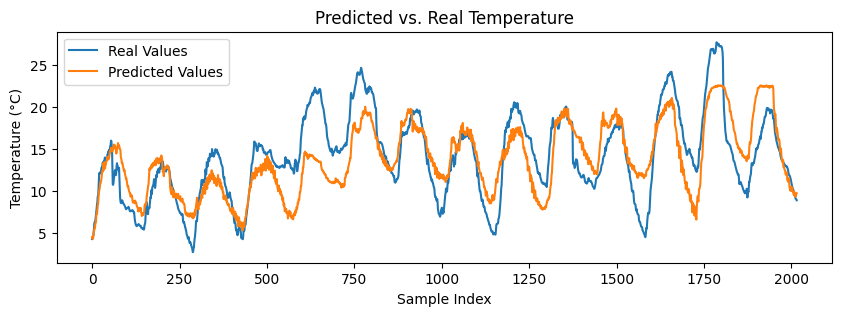

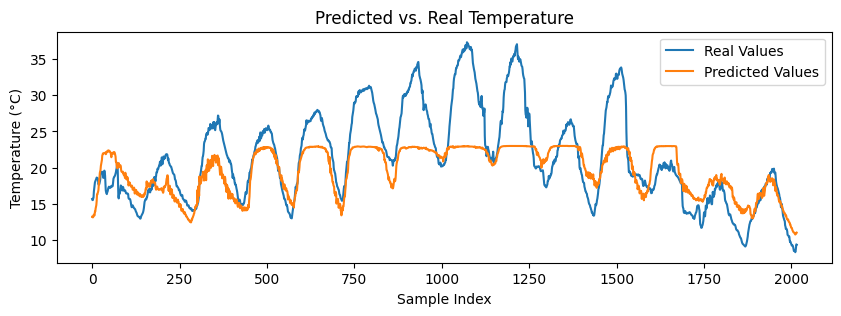

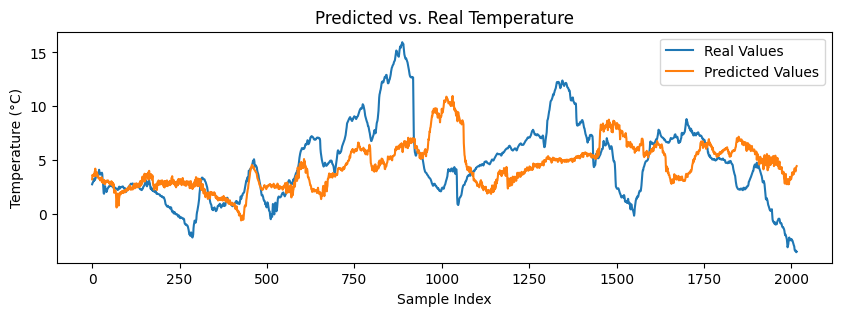

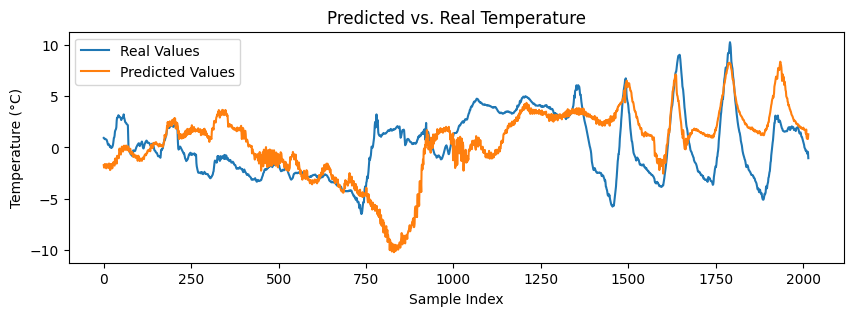

In [ ]:
model = keras.models.load_model("models/jena_gru.keras")
for start_index in [ (24*6)*4*29,  (24*6)*6*29, 24, (24*6)*1*29,]:
    plot_predictions(test_dataset, model, 24*6*14, start_index) # 14 days samples

## LSTM with dropout and gradient clipping

### Define the model

In [ ]:
import keras
from keras import layers

def get_regularized_LSTM_model():
    inputs = keras.Input(shape=(sequence_length, raw_data.shape[-1]))
    x = layers.LSTM(32, recurrent_dropout=0.25)(inputs) # change 16 -> 32.
    x = layers.Dropout(0.5)(x)                          # dropout
    outputs = layers.Dense(1)(x)
    model = keras.Model(inputs, outputs)
    return model

model = get_regularized_LSTM_model()
model.summary()

# optimizer= keras.optimizers.Adam(clipnorm=1.0)

Model: "functional_33"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_33 (InputLayer)     │ (None, 120, 14)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_11 (LSTM)                  │ (None, 32)             │         6,016 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_38 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,049 (23.63 KB)

 Trainable params: 6,049 (23.63 KB)

 Non-trainable params: 0 (0.00 B)

### Train the model

Epoch 1/30


/home/zuzka/test_tf/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


819/819 ━━━━━━━━━━━━━━━━━━━━ 79s 95ms/step - loss: 31.9057 - mae: 4.1352 - rmse: 5.6485 - val_loss: 9.7083 - val_mae: 2.4210 - val_rmse: 3.1158
Epoch 2/30
819/819 ━━━━━━━━━━━━━━━━━━━━ 79s 96ms/step - loss: 15.2716 - mae: 3.0354 - rmse: 3.9079 - val_loss: 9.3100 - val_mae: 2.3752 - val_rmse: 3.0512
Epoch 3/30
819/819 ━━━━━━━━━━━━━━━━━━━━ 78s 96ms/step - loss: 14.5559 - mae: 2.9589 - rmse: 3.8152 - val_loss: 9.0379 - val_mae: 2.3431 - val_rmse: 3.0063
Epoch 4/30
819/819 ━━━━━━━━━━━━━━━━━━━━ 78s 96ms/step - loss: 14.0394 - mae: 2.9058 - rmse: 3.7469 - val_loss: 8.8781 - val_mae: 2.3170 - val_rmse: 2.9796
Epoch 5/30
819/819 ━━━━━━━━━━━━━━━━━━━━ 78s 95ms/step - loss: 13.5506 - mae: 2.8478 - rmse: 3.6811 - val_loss: 8.9516 - val_mae: 2.3166 - val_rmse: 2.9919
Epoch 6/30
819/819 ━━━━━━━━━━━━━━━━━━━━ 78s 95ms/step - loss: 13.1203 - mae: 2.8078 - rmse: 3.6222 - val_loss: 8.9216 - val_mae: 2.3109 - val_rmse: 2.9869
Epoch 7/30
819/819 ━━━━━━━━━━━━━━━━━━━━ 78s 95ms/step - loss: 12.8070 - mae: 2.77

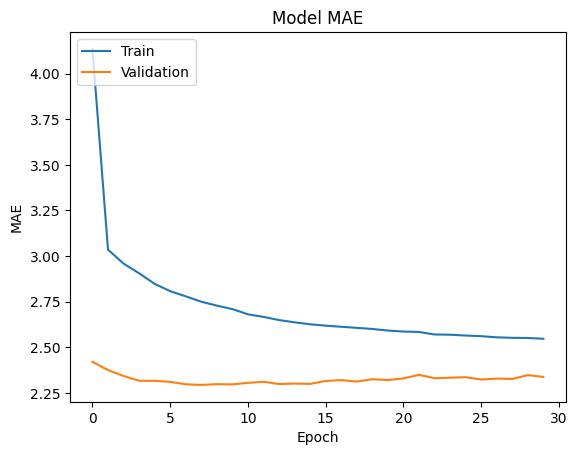

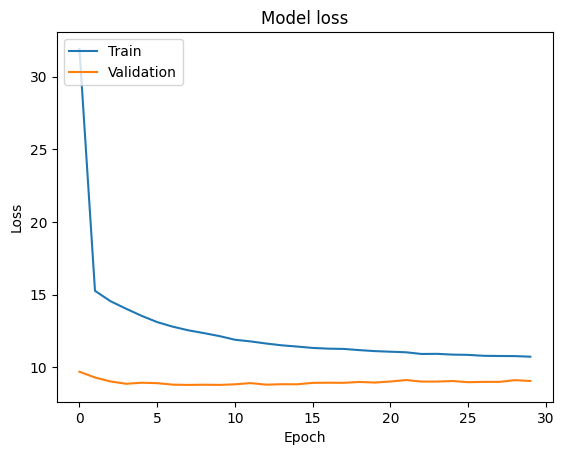

819/819 ━━━━━━━━━━━━━━━━━━━━ 23s 28ms/step - loss: 8.5971 - mae: 2.2870 - rmse: 2.9321
408/408 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - loss: 8.8003 - mae: 2.2941 - rmse: 2.9665
405/405 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - loss: 9.7970 - mae: 2.4604 - rmse: 3.1300
Train      MAE: 2.29, RMSE: 2.93
Validation MAE: 2.29, RMSE: 2.97
Test       MAE: 2.46, RMSE: 3.13
Results:


,Model Name,Details,Train MAE,Train RMSE,Val MAE,Val RMSE,Test MAE,Test RMSE,Epochs,Time (s)
0,Baseline,Previous day,2.691644,3.492441,2.441733,3.177835,2.622036,3.426826,0,-1.000000
1,jena_mlp.keras,,2.286377,2.912248,2.603380,3.286613,2.704371,3.433772,10,32.364558
2,jena_cnn.keras,,2.783204,3.503916,2.957596,3.758692,3.104005,3.930905,10,35.104710
3,jena_simpleRNN.keras,,2.451746,3.148395,2.317821,2.986339,2.475284,3.196283,10,79.530048
4,jena_lstm.keras,,2.282090,2.909583,2.364570,3.053765,2.518209,3.222106,20,105.702224
5,jena_gru.keras,,2.338784,3.019350,2.395717,3.107807,2.572892,3.284117,10,54.666981
6,jena_reg_lstm.keras,,2.286985,2.932089,2.294095,2.966535,2.460425,3.130014,30,2347.878815


In [ ]:
# Set some of the hyperparameters:
do_early_stopping = False
do_checkpoint = True
do_tensorboard = True
max_epochs = 30      # change !!!!!!!!!
model_name = "jena_reg_lstm.keras"
details = "" # your comment

###############################################
# Define the model architecture:
model = get_regularized_LSTM_model()

# Configure the model:
model.compile(optimizer= keras.optimizers.Adam(clipnorm=1.0),  # change !!!!!!
              loss= keras.losses.MeanSquaredError(),
              metrics= [keras.metrics.MeanAbsoluteError(name="mae"), keras.metrics.RootMeanSquaredError(name="rmse")])

# Define callbacks (e.g., early stopping):
callbacks = []
if do_early_stopping:
    from keras.callbacks import EarlyStopping
    early_stopping = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
    callbacks.append(early_stopping)
if do_checkpoint:
    from keras.callbacks import ModelCheckpoint
    checkpoint =     keras.callbacks.ModelCheckpoint(
        filepath="./models/" + model_name,
        save_best_only=True,
        monitor="val_loss")
    callbacks.append(checkpoint)
if do_tensorboard:
    from keras.callbacks import TensorBoard
    tensorboard_callback = TensorBoard(log_dir="./logs_jena/"+model_name, histogram_freq=1, write_steps_per_second=True)
    callbacks.append(tensorboard_callback)

################################################
# Train the model
import time
start_time = time.time()
history = model.fit(train_dataset,
                    epochs=max_epochs,
                    validation_data=val_dataset,
                    callbacks=callbacks)
time_fit = time.time() - start_time

###############################
# Plot the training progress:
plot_history(history)

if do_checkpoint:
    # Load the best model
    model = keras.models.load_model("./models/" + model_name)


# Evaluate the model on the training, validation and test sets
train_loss, train_mae, train_rmse = model.evaluate(train_dataset)
val_loss, val_mae, val_rmse = model.evaluate(val_dataset)
test_loss, test_mae, test_rmse = model.evaluate(test_dataset)

print(f"Train      MAE: {train_mae:.2f}, RMSE: {train_rmse:.2f}")
print(f"Validation MAE: {val_mae:.2f}, RMSE: {val_rmse:.2f}")
print(f"Test       MAE: {test_mae:.2f}, RMSE: {test_rmse:.2f}")

###############################
# Save the model:
import os
model_dir = "./models/"
if not os.path.exists(model_dir):
    os.makedirs(model_dir)
model.save(model_dir + model_name)

#################################
# Add results to the dataframe:
new_entry = {
    "Model Name" : model_name,
    "Details" : details,
    "Train MAE" : train_mae,
    "Val MAE" : val_mae,
    "Test MAE" : test_mae,
    "Train RMSE" : train_rmse,
    "Val RMSE" : val_rmse,
    "Test RMSE" : test_rmse,
    "Epochs": max_epochs,
    "Time (s)": time_fit,
}
if 'results_df' not in locals() or results_df is None or results_df.empty:
    results_df = pd.DataFrame([new_entry])
else:
  results_df = pd.concat([results_df, pd.DataFrame([new_entry])], ignore_index=True)

# View and and save the dataframe:
print("Results:")
display(results_df)
results_df.to_csv("models/jena_results.csv", index=False)


### Observe the results

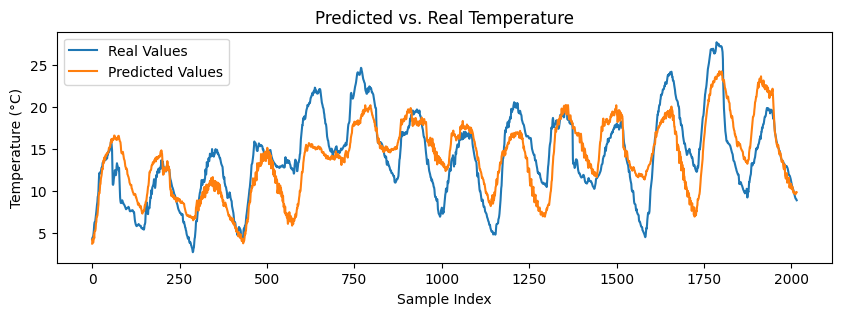

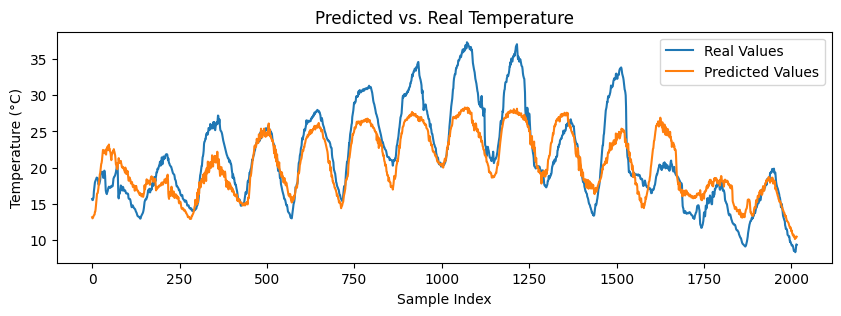

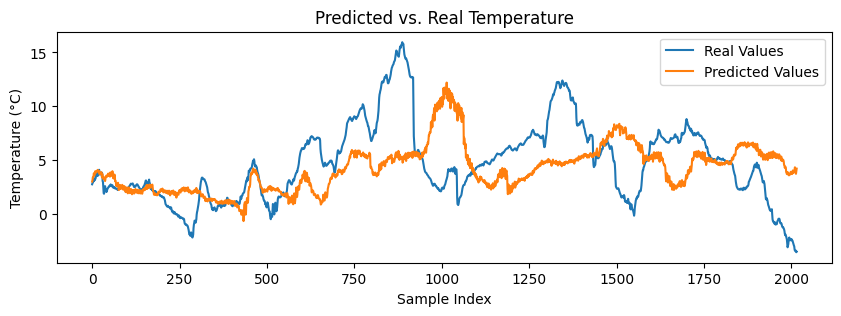

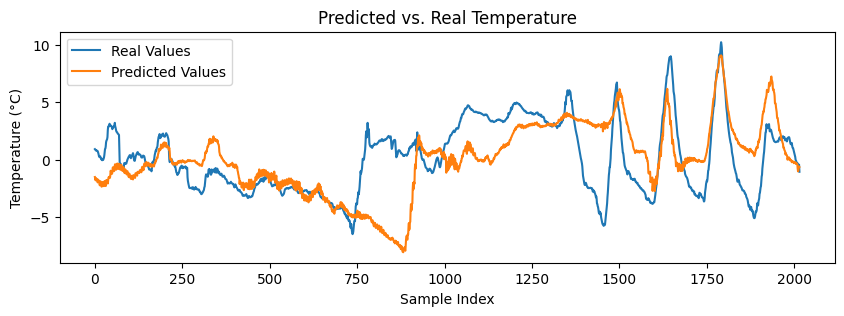

In [ ]:
model = keras.models.load_model("models/jena_reg_lstm.keras")
for start_index in [ (24*6)*4*29,  (24*6)*6*29, 24, (24*6)*1*29,]:
    plot_predictions(test_dataset, model, 24*6*14, start_index) # 14 days samples

In [ ]:
display(results_df)

,Model Name,Details,Train MAE,Train RMSE,Val MAE,Val RMSE,Test MAE,Test RMSE,Epochs,Time (s)
0,Baseline,Previous day,2.691644,3.492441,2.441733,3.177835,2.622036,3.426826,0,-1.000000
1,jena_mlp.keras,,2.286377,2.912248,2.603380,3.286613,2.704371,3.433772,10,32.364558
2,jena_cnn.keras,,2.783204,3.503916,2.957596,3.758692,3.104005,3.930905,10,35.104710
3,jena_simpleRNN.keras,,2.451746,3.148395,2.317821,2.986339,2.475284,3.196283,10,79.530048
4,jena_lstm.keras,,2.282090,2.909583,2.364570,3.053765,2.518209,3.222106,20,105.702224
5,jena_gru.keras,,2.338784,3.019350,2.395717,3.107807,2.572892,3.284117,10,54.666981
6,jena_reg_lstm.keras,,2.286985,2.932089,2.294095,2.966535,2.460425,3.130014,30,2347.878815


In [ ]:
#results_df = results_df.drop(6, axis=0).reset_index(drop=True)

## GRU with more layers

### Define the model

In [ ]:
import keras
from keras import layers

def get_layered_GRU_model():
    inputs = keras.Input(shape=(sequence_length, raw_data.shape[-1]))

    x = layers.GRU(16, return_sequences=True)(inputs)

    x = layers.GRU(16)(x)
    x = layers.Dropout(0.25)(x)
    outputs = layers.Dense(1)(x)
    model = keras.Model(inputs, outputs)
    return model

model = get_layered_GRU_model()
model.summary()

Model: "functional_35"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_35 (InputLayer)     │ (None, 120, 14)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_14 (GRU)                    │ (None, 120, 16)        │         1,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_15 (GRU)                    │ (None, 16)             │         1,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_40 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,185 (12.44 KB)

 Trainable params: 3,185 (12.44 KB)

 Non-trainable params: 0 (0.00 B)

### Train the model

Epoch 1/20


/home/zuzka/test_tf/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


819/819 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - loss: 38.8792 - mae: 4.5244 - rmse: 6.2353 - val_loss: 11.4458 - val_mae: 2.5407 - val_rmse: 3.3832
Epoch 2/20
819/819 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - loss: 13.0426 - mae: 2.7857 - rmse: 3.6115 - val_loss: 9.1293 - val_mae: 2.3356 - val_rmse: 3.0215
Epoch 3/20
819/819 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - loss: 12.0958 - mae: 2.6934 - rmse: 3.4779 - val_loss: 8.9642 - val_mae: 2.3208 - val_rmse: 2.9940
Epoch 4/20
819/819 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - loss: 11.6895 - mae: 2.6471 - rmse: 3.4190 - val_loss: 9.1366 - val_mae: 2.3484 - val_rmse: 3.0227
Epoch 5/20
819/819 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - loss: 11.2190 - mae: 2.5937 - rmse: 3.3495 - val_loss: 9.1753 - val_mae: 2.3484 - val_rmse: 3.0291
Epoch 6/20
819/819 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - loss: 10.7838 - mae: 2.5501 - rmse: 3.2839 - val_loss: 9.4425 - val_mae: 2.3860 - val_rmse: 3.0729
Epoch 7/20
819/819 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - loss: 10.4267 - mae: 2.5119 - r

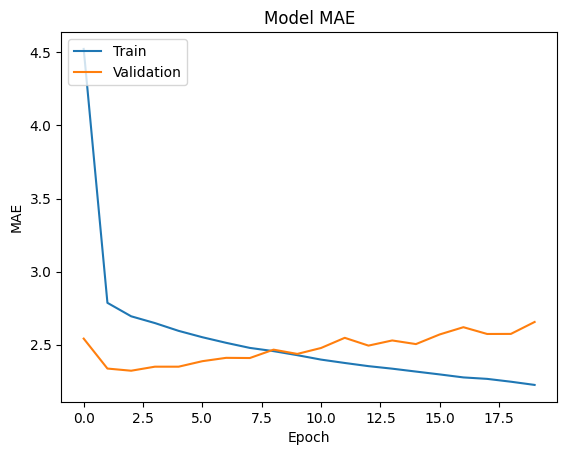

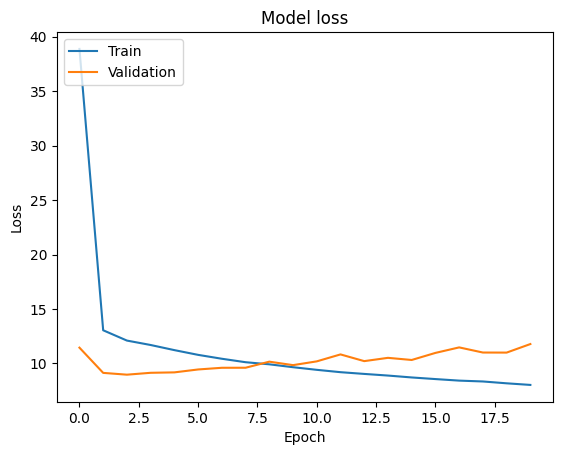

819/819 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 9.3278 - mae: 2.3749 - rmse: 3.0541
408/408 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 8.9642 - mae: 2.3208 - rmse: 2.9940
405/405 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 9.9614 - mae: 2.4734 - rmse: 3.1562 
Train      MAE: 2.37, RMSE: 3.05
Validation MAE: 2.32, RMSE: 2.99
Test       MAE: 2.47, RMSE: 3.16
Results:


,Model Name,Details,Train MAE,Train RMSE,Val MAE,Val RMSE,Test MAE,Test RMSE,Epochs,Time (s)
0,Baseline,Previous day,2.691644,3.492441,2.441733,3.177835,2.622036,3.426826,0,-1.000000
1,jena_mlp.keras,,2.286377,2.912248,2.603380,3.286613,2.704371,3.433772,10,32.364558
2,jena_cnn.keras,,2.783204,3.503916,2.957596,3.758692,3.104005,3.930905,10,35.104710
3,jena_simpleRNN.keras,,2.451746,3.148395,2.317821,2.986339,2.475284,3.196283,10,79.530048
4,jena_lstm.keras,,2.282090,2.909583,2.364570,3.053765,2.518209,3.222106,20,105.702224
5,jena_gru.keras,,2.338784,3.019350,2.395717,3.107807,2.572892,3.284117,10,54.666981
6,jena_reg_lstm.keras,,2.286985,2.932089,2.294095,2.966535,2.460425,3.130014,30,2347.878815
7,jena_layered_gru.keras,,2.374865,3.054150,2.320758,2.994034,2.473392,3.156168,20,162.025456


In [ ]:
# Set some of the hyperparameters:
do_early_stopping = False
do_checkpoint = True
do_tensorboard = True
max_epochs = 20      # change !!!!!!!!!
model_name = "jena_layered_gru.keras"
details = "" # your comment

###############################################
# Define the model architecture:
model = get_layered_GRU_model()

# Configure the model:
model.compile(optimizer= keras.optimizers.Adam(clipnorm=1.0),  # change !!!!!!
              loss= keras.losses.MeanSquaredError(),
              metrics= [keras.metrics.MeanAbsoluteError(name="mae"), keras.metrics.RootMeanSquaredError(name="rmse")])

# Define callbacks (e.g., early stopping):
callbacks = []
if do_early_stopping:
    from keras.callbacks import EarlyStopping
    early_stopping = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
    callbacks.append(early_stopping)
if do_checkpoint:
    from keras.callbacks import ModelCheckpoint
    checkpoint =     keras.callbacks.ModelCheckpoint(
        filepath="./models/" + model_name,
        save_best_only=True,
        monitor="val_loss")
    callbacks.append(checkpoint)
if do_tensorboard:
    from keras.callbacks import TensorBoard
    tensorboard_callback = TensorBoard(log_dir="./logs_jena/"+model_name, histogram_freq=1, write_steps_per_second=True)
    callbacks.append(tensorboard_callback)

################################################
# Train the model
import time
start_time = time.time()
history = model.fit(train_dataset,
                    epochs=max_epochs,
                    validation_data=val_dataset,
                    callbacks=callbacks)
time_fit = time.time() - start_time

###############################
# Plot the training progress:
plot_history(history)

if do_checkpoint:
    # Load the best model
    model = keras.models.load_model("./models/" + model_name)


# Evaluate the model on the training, validation and test sets
train_loss, train_mae, train_rmse = model.evaluate(train_dataset)
val_loss, val_mae, val_rmse = model.evaluate(val_dataset)
test_loss, test_mae, test_rmse = model.evaluate(test_dataset)

print(f"Train      MAE: {train_mae:.2f}, RMSE: {train_rmse:.2f}")
print(f"Validation MAE: {val_mae:.2f}, RMSE: {val_rmse:.2f}")
print(f"Test       MAE: {test_mae:.2f}, RMSE: {test_rmse:.2f}")

###############################
# Save the model:
import os
model_dir = "./models/"
if not os.path.exists(model_dir):
    os.makedirs(model_dir)
model.save(model_dir + model_name)

#################################
# Add results to the dataframe:
new_entry = {
    "Model Name" : model_name,
    "Details" : details,
    "Train MAE" : train_mae,
    "Val MAE" : val_mae,
    "Test MAE" : test_mae,
    "Train RMSE" : train_rmse,
    "Val RMSE" : val_rmse,
    "Test RMSE" : test_rmse,
    "Epochs": max_epochs,
    "Time (s)": time_fit,
}
if 'results_df' not in locals() or results_df is None or results_df.empty:
    results_df = pd.DataFrame([new_entry])
else:
  results_df = pd.concat([results_df, pd.DataFrame([new_entry])], ignore_index=True)

# View and and save the dataframe:
print("Results:")
display(results_df)
results_df.to_csv("models/jena_results.csv", index=False)



### Observe the results

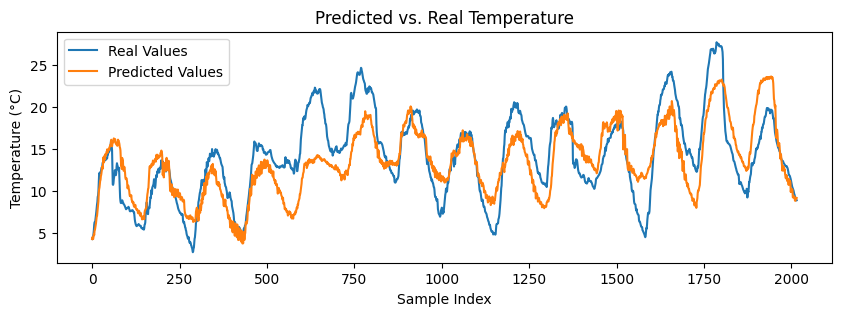

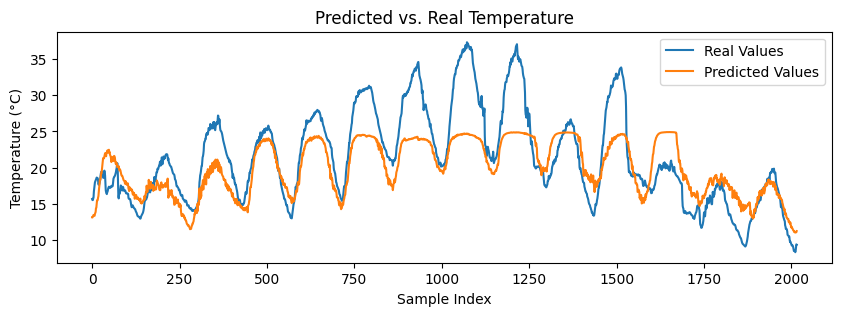

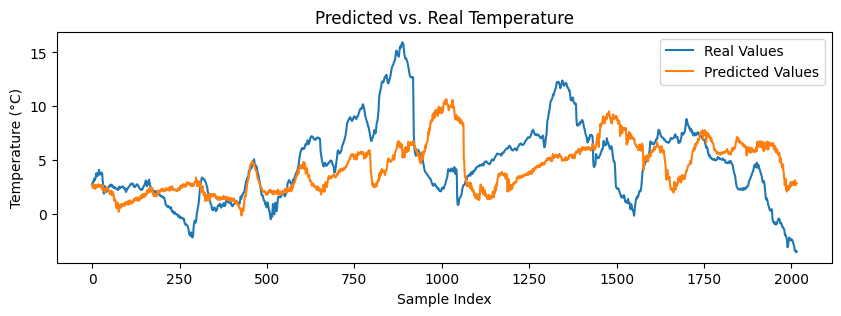

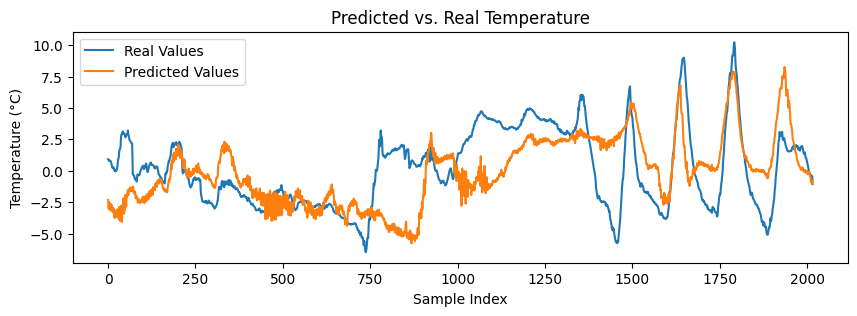

In [ ]:
model = keras.models.load_model("models/jena_layered_gru.keras")
for start_index in [ (24*6)*4*29,  (24*6)*6*29, 24, (24*6)*1*29,]:
    plot_predictions(test_dataset, model, 24*6*14, start_index) # 14 days samples

## Layer normalized model

### Define the model

In [ ]:
import keras
from keras import layers

def get_layer_norm_GRU_model():
    inputs = keras.Input(shape=(sequence_length, raw_data.shape[-1]))

    x = layers.GRU(16, return_sequences=True)(inputs)
    x = layers.LayerNormalization()(x)

    x = layers.GRU(16)(x)
    x = layers.LayerNormalization()(x)

    outputs = layers.Dense(1)(x)
    model = keras.Model(inputs, outputs)
    return model
model = get_layer_norm_GRU_model()
model.summary()



Model: "functional_37"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_37 (InputLayer)     │ (None, 120, 14)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_18 (GRU)                    │ (None, 120, 16)        │         1,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization_4           │ (None, 120, 16)        │            32 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_19 (GRU)                    │ (None, 16)             │         1,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization_5           │ (None, 16)             │            32 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_42 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,249 (12.69 KB)

 Trainable params: 3,249 (12.69 KB)

 Non-trainable params: 0 (0.00 B)

### Train the model

Epoch 1/20


/home/zuzka/test_tf/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


819/819 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - loss: 23.4008 - mae: 3.4204 - rmse: 4.8374 - val_loss: 8.9202 - val_mae: 2.3092 - val_rmse: 2.9867
Epoch 2/20
819/819 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - loss: 9.0262 - mae: 2.3439 - rmse: 3.0044 - val_loss: 8.8483 - val_mae: 2.3099 - val_rmse: 2.9746
Epoch 3/20
819/819 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - loss: 8.4442 - mae: 2.2728 - rmse: 2.9059 - val_loss: 9.1120 - val_mae: 2.3585 - val_rmse: 3.0186
Epoch 4/20
819/819 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - loss: 7.9660 - mae: 2.2104 - rmse: 2.8224 - val_loss: 9.3098 - val_mae: 2.3789 - val_rmse: 3.0512
Epoch 5/20
819/819 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - loss: 7.5934 - mae: 2.1592 - rmse: 2.7556 - val_loss: 9.7508 - val_mae: 2.4415 - val_rmse: 3.1226
Epoch 6/20
819/819 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - loss: 7.2721 - mae: 2.1162 - rmse: 2.6967 - val_loss: 9.8313 - val_mae: 2.4367 - val_rmse: 3.1355
Epoch 7/20
819/819 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - loss: 6.9371 - mae: 2.0711 - rmse: 2

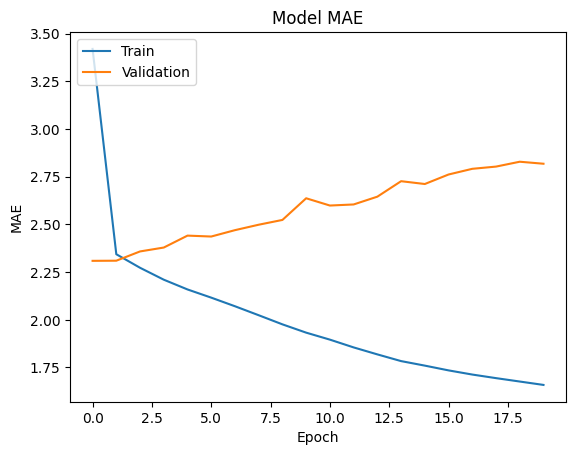

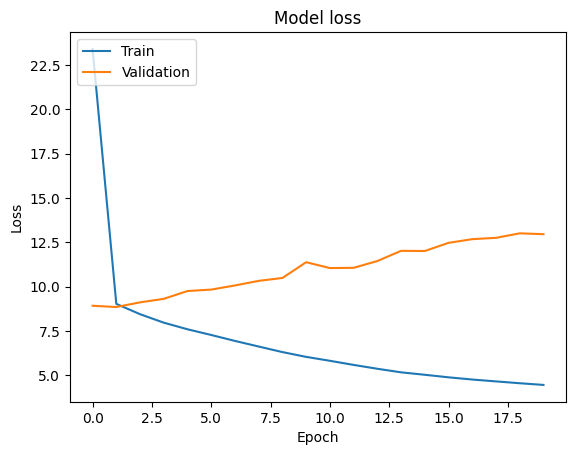

819/819 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 8.6861 - mae: 2.2983 - rmse: 2.9472
408/408 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 8.8483 - mae: 2.3099 - rmse: 2.9746
405/405 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 9.8147 - mae: 2.4663 - rmse: 3.1328
Train      MAE: 2.30, RMSE: 2.95
Validation MAE: 2.31, RMSE: 2.97
Test       MAE: 2.47, RMSE: 3.13
Results:


,Model Name,Details,Train MAE,Train RMSE,Val MAE,Val RMSE,Test MAE,Test RMSE,Epochs,Time (s)
0,Baseline,Previous day,2.691644,3.492441,2.441733,3.177835,2.622036,3.426826,0,-1.000000
1,jena_mlp.keras,,2.286377,2.912248,2.603380,3.286613,2.704371,3.433772,10,32.364558
2,jena_cnn.keras,,2.783204,3.503916,2.957596,3.758692,3.104005,3.930905,10,35.104710
3,jena_simpleRNN.keras,,2.451746,3.148395,2.317821,2.986339,2.475284,3.196283,10,79.530048
4,jena_lstm.keras,,2.282090,2.909583,2.364570,3.053765,2.518209,3.222106,20,105.702224
5,jena_gru.keras,,2.338784,3.019350,2.395717,3.107807,2.572892,3.284117,10,54.666981
6,jena_reg_lstm.keras,,2.286985,2.932089,2.294095,2.966535,2.460425,3.130014,30,2347.878815
7,jena_layered_gru.keras,,2.374865,3.054150,2.320758,2.994034,2.473392,3.156168,20,162.025456
8,jena_layer_norm_GRU.keras,,2.298309,2.947223,2.309939,2.974610,2.466337,3.132850,20,174.238538


In [ ]:
# Set some of the hyperparameters:
do_early_stopping = False
do_checkpoint = True
do_tensorboard = True
max_epochs = 20      # change !!!!!!!!!
model_name = "jena_layer_norm_GRU.keras"
details = "" # your comment

###############################################
# Define the model architecture:
model = get_layer_norm_GRU_model()

# Configure the model:
model.compile(optimizer= keras.optimizers.Adam(clipnorm=1.0),  # change !!!!!!
              loss= keras.losses.MeanSquaredError(),
              metrics= [keras.metrics.MeanAbsoluteError(name="mae"), keras.metrics.RootMeanSquaredError(name="rmse")])

# Define callbacks (e.g., early stopping):
callbacks = []
if do_early_stopping:
    from keras.callbacks import EarlyStopping
    early_stopping = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
    callbacks.append(early_stopping)
if do_checkpoint:
    from keras.callbacks import ModelCheckpoint
    checkpoint =     keras.callbacks.ModelCheckpoint(
        filepath="./models/" + model_name,
        save_best_only=True,
        monitor="val_loss")
    callbacks.append(checkpoint)
if do_tensorboard:
    from keras.callbacks import TensorBoard
    tensorboard_callback = TensorBoard(log_dir="./logs_jena/"+model_name, histogram_freq=1, write_steps_per_second=True)
    callbacks.append(tensorboard_callback)

################################################
# Train the model
import time
start_time = time.time()
history = model.fit(train_dataset,
                    epochs=max_epochs,
                    validation_data=val_dataset,
                    callbacks=callbacks)
time_fit = time.time() - start_time

###############################
# Plot the training progress:
plot_history(history)

if do_checkpoint:
    # Load the best model
    model = keras.models.load_model("./models/" + model_name)


# Evaluate the model on the training, validation and test sets
train_loss, train_mae, train_rmse = model.evaluate(train_dataset)
val_loss, val_mae, val_rmse = model.evaluate(val_dataset)
test_loss, test_mae, test_rmse = model.evaluate(test_dataset)

print(f"Train      MAE: {train_mae:.2f}, RMSE: {train_rmse:.2f}")
print(f"Validation MAE: {val_mae:.2f}, RMSE: {val_rmse:.2f}")
print(f"Test       MAE: {test_mae:.2f}, RMSE: {test_rmse:.2f}")

###############################
# Save the model:
import os
model_dir = "./models/"
if not os.path.exists(model_dir):
    os.makedirs(model_dir)
model.save(model_dir + model_name)

#################################
# Add results to the dataframe:
new_entry = {
    "Model Name" : model_name,
    "Details" : details,
    "Train MAE" : train_mae,
    "Val MAE" : val_mae,
    "Test MAE" : test_mae,
    "Train RMSE" : train_rmse,
    "Val RMSE" : val_rmse,
    "Test RMSE" : test_rmse,
    "Epochs": max_epochs,
    "Time (s)": time_fit,
}
if 'results_df' not in locals() or results_df is None or results_df.empty:
    results_df = pd.DataFrame([new_entry])
else:
  results_df = pd.concat([results_df, pd.DataFrame([new_entry])], ignore_index=True)

# View and and save the dataframe:
print("Results:")
display(results_df)
results_df.to_csv("models/jena_results.csv", index=False)



### Observe the results

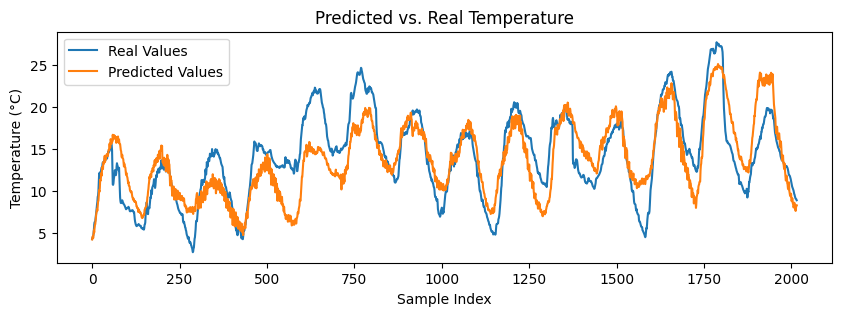

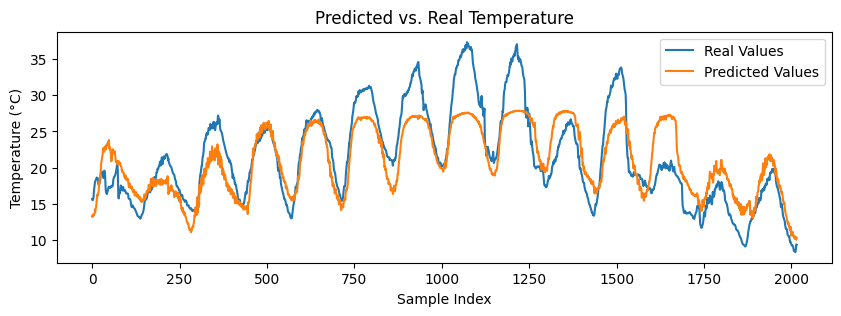

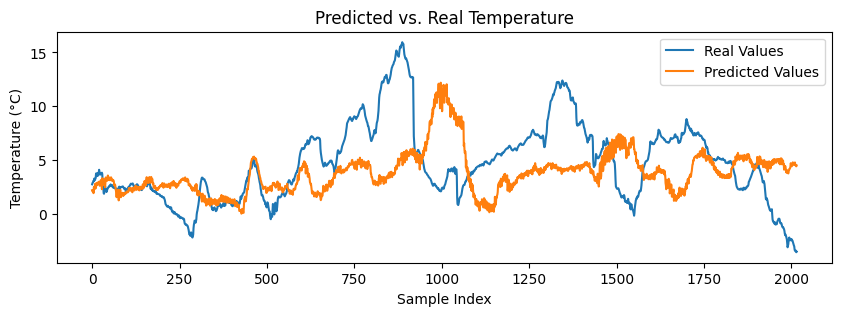

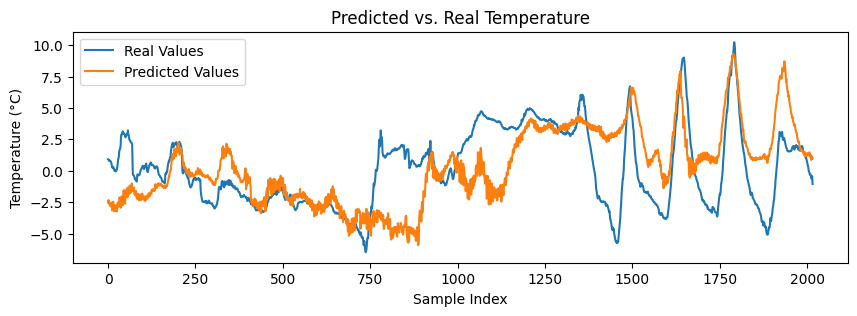

In [ ]:
model = keras.models.load_model("models/jena_layer_norm_GRU.keras")
for start_index in [ (24*6)*4*29,  (24*6)*6*29, 24, (24*6)*1*29,]:
    plot_predictions(test_dataset, model, 24*6*14, start_index) # 14 days samples

## Bidirectional RNN

### Define the model

In [ ]:
import keras
from keras import layers

def get_bi_LSTM_model():
    inputs = keras.Input(shape=(sequence_length, raw_data.shape[-1]))
    x = layers.Bidirectional(layers.LSTM(16))(inputs)
    outputs = layers.Dense(1)(x)
    model = keras.Model(inputs, outputs)
    return model

model = get_bi_LSTM_model()
model.summary()

# optimizer= keras.optimizers.Adam(clipnorm=1.0)

Model: "functional_39"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_39 (InputLayer)     │ (None, 120, 14)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 32)             │         3,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_44 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,001 (15.63 KB)

 Trainable params: 4,001 (15.63 KB)

 Non-trainable params: 0 (0.00 B)

### Train the model

Epoch 1/10


/home/zuzka/test_tf/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


819/819 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - loss: 38.5397 - mae: 4.4993 - rmse: 6.2080 - val_loss: 11.2365 - val_mae: 2.5198 - val_rmse: 3.3521
Epoch 2/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - loss: 12.8780 - mae: 2.7762 - rmse: 3.5886 - val_loss: 9.0385 - val_mae: 2.3252 - val_rmse: 3.0064
Epoch 3/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - loss: 11.8224 - mae: 2.6650 - rmse: 3.4384 - val_loss: 8.8420 - val_mae: 2.3029 - val_rmse: 2.9735
Epoch 4/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - loss: 11.2140 - mae: 2.6006 - rmse: 3.3487 - val_loss: 8.8638 - val_mae: 2.3121 - val_rmse: 2.9772
Epoch 5/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - loss: 10.7535 - mae: 2.5510 - rmse: 3.2792 - val_loss: 9.0446 - val_mae: 2.3397 - val_rmse: 3.0074
Epoch 6/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - loss: 10.3016 - mae: 2.5009 - rmse: 3.2096 - val_loss: 9.1283 - val_mae: 2.3450 - val_rmse: 3.0213
Epoch 7/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - loss: 10.0066 - mae: 2.4652 - r

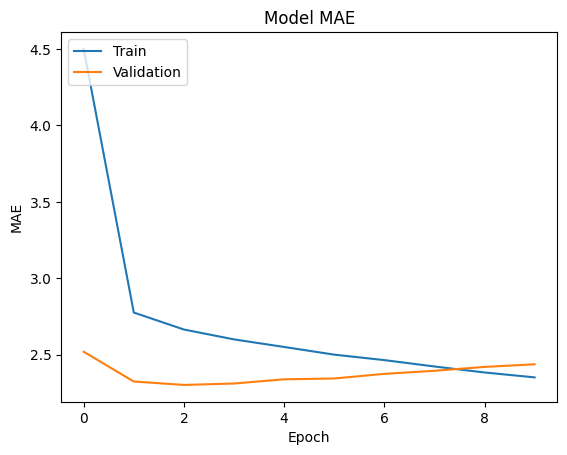

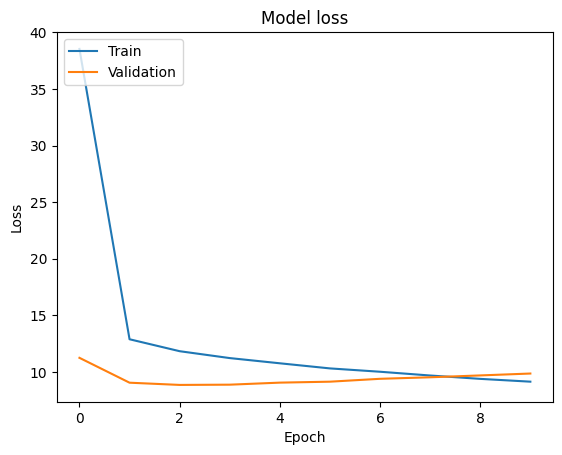

819/819 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 8.9287 - mae: 2.3330 - rmse: 2.9881
408/408 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 8.8420 - mae: 2.3029 - rmse: 2.9735
405/405 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 9.9644 - mae: 2.4753 - rmse: 3.1567
Train      MAE: 2.33, RMSE: 2.99
Validation MAE: 2.30, RMSE: 2.97
Test       MAE: 2.48, RMSE: 3.16
Results:


,Model Name,Details,Train MAE,Train RMSE,Val MAE,Val RMSE,Test MAE,Test RMSE,Epochs,Time (s)
0,Baseline,Previous day,2.691644,3.492441,2.441733,3.177835,2.622036,3.426826,0,-1.000000
1,jena_mlp.keras,,2.286377,2.912248,2.603380,3.286613,2.704371,3.433772,10,32.364558
2,jena_cnn.keras,,2.783204,3.503916,2.957596,3.758692,3.104005,3.930905,10,35.104710
3,jena_simpleRNN.keras,,2.451746,3.148395,2.317821,2.986339,2.475284,3.196283,10,79.530048
4,jena_lstm.keras,,2.282090,2.909583,2.364570,3.053765,2.518209,3.222106,20,105.702224
5,jena_gru.keras,,2.338784,3.019350,2.395717,3.107807,2.572892,3.284117,10,54.666981
6,jena_reg_lstm.keras,,2.286985,2.932089,2.294095,2.966535,2.460425,3.130014,30,2347.878815
7,jena_layered_gru.keras,,2.374865,3.054150,2.320758,2.994034,2.473392,3.156168,20,162.025456
8,jena_layer_norm_GRU.keras,,2.298309,2.947223,2.309939,2.974610,2.466337,3.132850,20,174.238538
9,jena_bi_lstm.keras,,2.332973,2.988096,2.302931,2.973547,2.475255,3.156651,10,80.944701


In [ ]:
# Set some of the hyperparameters:
do_early_stopping = False
do_checkpoint = True
do_tensorboard = True
max_epochs = 10      # change !!!!!!!!!
model_name = "jena_bi_lstm.keras"
details = "" # your comment

###############################################
# Define the model architecture:
model = get_layered_GRU_model()

# Configure the model:
model.compile(optimizer= keras.optimizers.Adam(clipnorm=1.0),  # change !!!!!!
              loss= keras.losses.MeanSquaredError(),
              metrics= [keras.metrics.MeanAbsoluteError(name="mae"), keras.metrics.RootMeanSquaredError(name="rmse")])

# Define callbacks (e.g., early stopping):
callbacks = []
if do_early_stopping:
    from keras.callbacks import EarlyStopping
    early_stopping = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
    callbacks.append(early_stopping)
if do_checkpoint:
    from keras.callbacks import ModelCheckpoint
    checkpoint =     keras.callbacks.ModelCheckpoint(
        filepath="./models/" + model_name,
        save_best_only=True,
        monitor="val_loss")
    callbacks.append(checkpoint)
if do_tensorboard:
    from keras.callbacks import TensorBoard
    tensorboard_callback = TensorBoard(log_dir="./logs_jena/"+model_name, histogram_freq=1, write_steps_per_second=True)
    callbacks.append(tensorboard_callback)

################################################
# Train the model
import time
start_time = time.time()
history = model.fit(train_dataset,
                    epochs=max_epochs,
                    validation_data=val_dataset,
                    callbacks=callbacks)
time_fit = time.time() - start_time

###############################
# Plot the training progress:
plot_history(history)

if do_checkpoint:
    # Load the best model
    model = keras.models.load_model("./models/" + model_name)


# Evaluate the model on the training, validation and test sets
train_loss, train_mae, train_rmse = model.evaluate(train_dataset)
val_loss, val_mae, val_rmse = model.evaluate(val_dataset)
test_loss, test_mae, test_rmse = model.evaluate(test_dataset)

print(f"Train      MAE: {train_mae:.2f}, RMSE: {train_rmse:.2f}")
print(f"Validation MAE: {val_mae:.2f}, RMSE: {val_rmse:.2f}")
print(f"Test       MAE: {test_mae:.2f}, RMSE: {test_rmse:.2f}")

###############################
# Save the model:
import os
model_dir = "./models/"
if not os.path.exists(model_dir):
    os.makedirs(model_dir)
model.save(model_dir + model_name)

#################################
# Add results to the dataframe:
new_entry = {
    "Model Name" : model_name,
    "Details" : details,
    "Train MAE" : train_mae,
    "Val MAE" : val_mae,
    "Test MAE" : test_mae,
    "Train RMSE" : train_rmse,
    "Val RMSE" : val_rmse,
    "Test RMSE" : test_rmse,
    "Epochs": max_epochs,
    "Time (s)": time_fit,
}
if 'results_df' not in locals() or results_df is None or results_df.empty:
    results_df = pd.DataFrame([new_entry])
else:
  results_df = pd.concat([results_df, pd.DataFrame([new_entry])], ignore_index=True)

# View and and save the dataframe:
print("Results:")
display(results_df)
results_df.to_csv("models/jena_results.csv", index=False)


### Observe the results

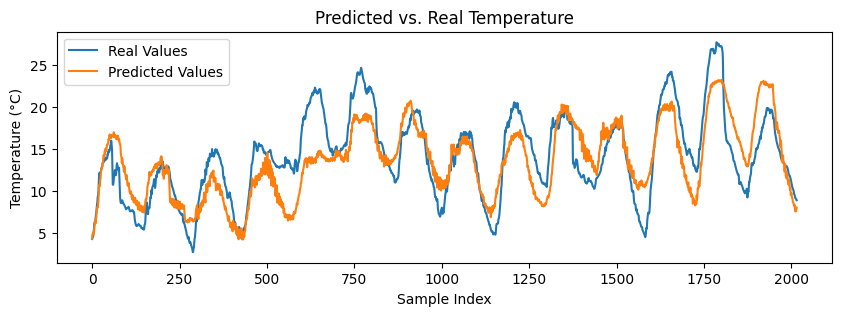

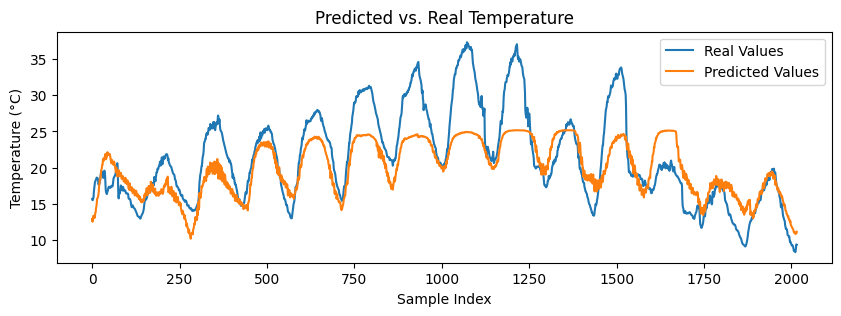

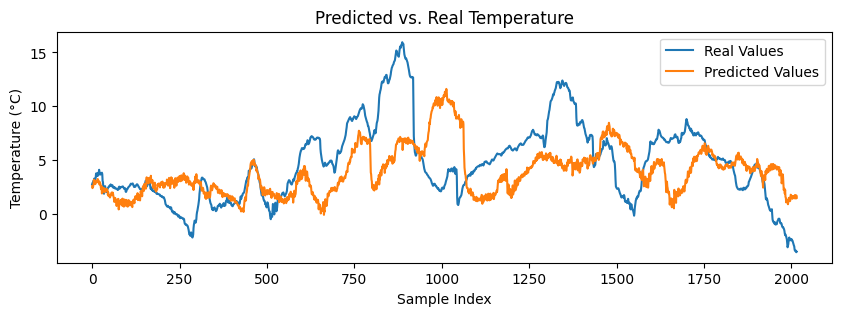

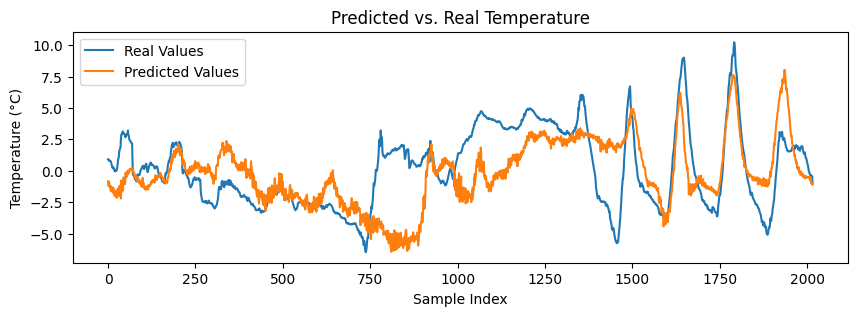

In [ ]:
model = keras.models.load_model("models/jena_bi_lstm.keras")
for start_index in [ (24*6)*4*29,  (24*6)*6*29, 24, (24*6)*1*29,]:
    plot_predictions(test_dataset, model, 24*6*14, start_index) # 14 days samples

In [ ]:
display(results_df)

,Model Name,Details,Train MAE,Train RMSE,Val MAE,Val RMSE,Test MAE,Test RMSE,Epochs,Time (s)
0,Baseline,Previous day,2.691644,3.492441,2.441733,3.177835,2.622036,3.426826,0,-1.000000
1,jena_mlp.keras,,2.286377,2.912248,2.603380,3.286613,2.704371,3.433772,10,32.364558
2,jena_cnn.keras,,2.783204,3.503916,2.957596,3.758692,3.104005,3.930905,10,35.104710
3,jena_simpleRNN.keras,,2.451746,3.148395,2.317821,2.986339,2.475284,3.196283,10,79.530048
4,jena_lstm.keras,,2.282090,2.909583,2.364570,3.053765,2.518209,3.222106,20,105.702224
5,jena_gru.keras,,2.338784,3.019350,2.395717,3.107807,2.572892,3.284117,10,54.666981
6,jena_reg_lstm.keras,,2.286985,2.932089,2.294095,2.966535,2.460425,3.130014,30,2347.878815
7,jena_layered_gru.keras,,2.374865,3.054150,2.320758,2.994034,2.473392,3.156168,20,162.025456
8,jena_layer_norm_GRU.keras,,2.298309,2.947223,2.309939,2.974610,2.466337,3.132850,20,174.238538
9,jena_bi_lstm.keras,,2.332973,2.988096,2.302931,2.973547,2.475255,3.156651,10,80.944701


In [ ]:
###############################################
# Load TensorBoard notebook extension
%load_ext tensorboard

# Start TensorBoard before training begins
%tensorboard --logdir logs_jena  --reload_interval=1

The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard


ERROR: Could not find `tensorboard`. Please ensure that your PATH
contains an executable `tensorboard` program, or explicitly specify
the path to a TensorBoard binary by setting the `TENSORBOARD_BINARY`
environment variable.